# Phase 3 – Machine Learning
## Step 1 – Feature Selection

**Task:** supervised regression – predict `avg_monthly_elec_bill` (reported bill in rupees, not kWh).

**Rules for the first experiment**
- Use only households whose bill was originally observed (9,469 rows).
- Exclude the target-leakage columns identified in the EDA audit.
- Do not overwrite the processed dataset (`output/analysis_ready_data.csv`).


### Cell 1 – Load data, build `modelling_df`, check leakage

In [364]:
import pandas as pd
from pathlib import Path

# 1. Find and load the processed dataset (does not modify it)

candidates = [
    Path("output/analysis_ready_data.csv"),
    Path("../output/analysis_ready_data.csv")
]

data_path = next(
    (p for p in candidates if p.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        f"Dataset not found. Current directory: {Path.cwd()}"
    )

df = pd.read_csv(data_path, low_memory=False)

print("Loaded:", data_path.resolve())
print("Dataset shape:", df.shape)


# 2. Keep only rows where the bill was originally observed

TARGET = "avg_monthly_elec_bill"
FLAG = "avg_monthly_elec_bill_was_missing"

# Check whether required columns exist
required_columns = [TARGET, FLAG]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise KeyError(f"Required columns not found: {missing_columns}")

# Select originally observed target values
observed = (
    df[FLAG]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("false")
)


# 3. Leakage columns identified during the EDA audit

LEAKAGE_COLS = [
    "q315_a_bill_mar_jun",
    "q315_b_bill_jul_oct",
    "q315_c_bill_nov_feb",
    "elec_bill_per_member",
    "bill_share_of_expenditure_pct",
    "bill_group",
    "state_bill_rank",
    "household_bill_rank",
    "avg_monthly_elec_bill_was_missing",
    "q610_c_billed_amount"
]

present = [
    col for col in LEAKAGE_COLS
    if col in df.columns
]

absent = [
    col for col in LEAKAGE_COLS
    if col not in df.columns
]

# Create a separate modelling dataset
modelling_df = (
    df.loc[observed]
    .drop(columns=present)
    .copy()
)


# 4. Basic checks

print("\nModelling rows:", len(modelling_df), "(expected 9,469)")
print(
    "Missing target values:",
    modelling_df[TARGET].isna().sum(),
    "(expected 0)"
)

print("Leakage columns dropped:", len(present))
print("Columns not found in data:", absent)

print("\nColumn types:")
print(modelling_df.dtypes.astype(str).value_counts())


# 5. Extra leakage scan:
# Identify remaining columns that may be related to bills or expenditure

keywords = [
    "bill",
    "billed",
    "amount",
    "expend",
    "per_member"
]

suspects = [
    col for col in modelling_df.columns
    if any(keyword in col.lower() for keyword in keywords)
    and col != TARGET
]

print("\nColumns to review for possible leakage:")

for col in suspects:
    print(" -", col)

Loaded: C:\Users\Prithvi Vinayak P\Downloads\CEEW_ETL_Team_Package\CEEW_Energy_ETL\output\analysis_ready_data.csv
Dataset shape: (14851, 341)

Modelling rows: 9469 (expected 9,469)
Missing target values: 0 (expected 0)
Leakage columns dropped: 10
Columns not found in data: []

Column types:
float64    263
int64       54
str         12
bool         2
Name: count, dtype: int64

Columns to review for possible leakage:
 - monthly_expenditure
 - q313_grid_billfreq
 - q407_led_purch_reason_lessbill_5
 - q608_b_ifprep_elec_bill_change
 - q608_c_ifprep_wrong_bill
 - q610_elec_bill_physical_yn
 - q610_a_no_billing_days
 - q610_b_billed_units
 - q610_e_bill_date
 - q610_e_bill_month
 - q610_e_bill_year
 - q613_picture_bill_yn
 - monthly_expenditure_was_missing
 - expenditure_per_member
 - expenditure_group


In [365]:
# Inspect all suspicious columns

# Inspect all suspicious columns in detail

print("Total suspicious columns:", len(suspects))

for col in suspects:
    print("\nColumn:", col)
    print("Data type:", modelling_df[col].dtype)
    print("Missing values:", modelling_df[col].isna().sum())
    print("Unique values:", modelling_df[col].nunique())
    print("Sample values:", modelling_df[col].dropna().unique()[:5])

Total suspicious columns: 15

Column: monthly_expenditure
Data type: float64
Missing values: 0
Unique values: 57
Sample values: [1558. 5000. 6000. 3000. 4000.]

Column: q313_grid_billfreq
Data type: float64
Missing values: 0
Unique values: 9
Sample values: [1. 2. 6. 5. 4.]

Column: q407_led_purch_reason_lessbill_5
Data type: float64
Missing values: 953
Unique values: 2
Sample values: [0. 1.]

Column: q608_b_ifprep_elec_bill_change
Data type: float64
Missing values: 8536
Unique values: 3
Sample values: [1. 3. 2.]

Column: q608_c_ifprep_wrong_bill
Data type: float64
Missing values: 8557
Unique values: 2
Sample values: [0. 1.]

Column: q610_elec_bill_physical_yn
Data type: float64
Missing values: 5
Unique values: 2
Sample values: [1. 0.]

Column: q610_a_no_billing_days
Data type: float64
Missing values: 6162
Unique values: 54
Sample values: [28. 31. 30. 61. 29.]

Column: q610_b_billed_units
Data type: float64
Missing values: 6248
Unique values: 428
Sample values: [ 12.  95.  93. 154. 143.

In [366]:
# Complete suspicious-column summary

summary_rows = []

for col in suspects:
    column_data = modelling_df[col]

    sample_values = (
        column_data.dropna()
        .unique()[:5]
        .tolist()
    )

    summary_rows.append({
        "Column": col,
        "Data Type": str(column_data.dtype),
        "Missing Count": column_data.isna().sum(),
        "Missing (%)": round(
            column_data.isna().mean() * 100, 2
        ),
        "Unique Values": column_data.nunique(),
        "Sample Values": sample_values
    })

suspect_summary = pd.DataFrame(summary_rows)

# Display all rows without truncation
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", 100,
    "display.width", 200
):
    display(suspect_summary)

,Column,Data Type,Missing Count,Missing (%),Unique Values,Sample Values
0,monthly_expenditure,float64,0,0.00,57,"[1557.9999999999998, 5000.0, 6000.0, 3000.0, 4000.0]"
1,q313_grid_billfreq,float64,0,0.00,9,"[1.0, 2.0, 6.0, 5.0, 4.0]"
2,q407_led_purch_reason_lessbill_5,float64,953,10.06,2,"[0.0, 1.0]"
3,q608_b_ifprep_elec_bill_change,float64,8536,90.15,3,"[1.0, 3.0, 2.0]"
4,q608_c_ifprep_wrong_bill,float64,8557,90.37,2,"[0.0, 1.0]"
5,q610_elec_bill_physical_yn,float64,5,0.05,2,"[1.0, 0.0]"
6,q610_a_no_billing_days,float64,6162,65.08,54,"[28.0, 31.0, 30.0, 61.0, 29.0]"
7,q610_b_billed_units,float64,6248,65.98,428,"[12.0, 95.0, 93.0, 154.0, 143.0]"
8,q610_e_bill_date,float64,6100,64.42,31,"[4.0, 5.0, 6.0, 9.0, 12.0]"
9,q610_e_bill_month,float64,6100,64.42,12,"[3.0, 11.0, 12.0, 8.0, 10.0]"


In [367]:
# Create our candidate modelling dataset

# Finalize the initial leakage exclusions.

# 1. Additional columns to exclude

ADDITIONAL_DROP_COLS = [
    "monthly_expenditure",
    "monthly_expenditure_was_missing",
    "expenditure_per_member",
    "expenditure_group",
    "q608_b_ifprep_elec_bill_change",
    "q608_c_ifprep_wrong_bill"
]

# 2. Exclude all recent electricity-bill detail columns

bill_detail_cols = [
    col for col in modelling_df.columns
    if col.startswith(("q610_", "q613_"))
]

# 3. Combine all exclusion lists

drop_cols = sorted(
    set(ADDITIONAL_DROP_COLS + bill_detail_cols)
    .intersection(modelling_df.columns)
)

# 4. Create candidate feature dataset

X_candidate = modelling_df.drop(
    columns=[TARGET] + drop_cols
)

y = modelling_df[TARGET].copy()

# 5. Display results

print("Original modelling dataset:", modelling_df.shape)

print("Columns additionally removed:", len(drop_cols))

print("\nCandidate feature dataset:", X_candidate.shape)

print("Target dataset:", y.shape)

print("\nRemaining suspicious columns:")

remaining_suspects = [
    col for col in X_candidate.columns
    if any(
        keyword in col.lower()
        for keyword in ["bill", "billed", "amount", "expend", "per_member"]
    )
]

for col in remaining_suspects:
    print("-", col)

Original modelling dataset: (9469, 331)
Columns additionally removed: 15

Candidate feature dataset: (9469, 315)
Target dataset: (9469,)

Remaining suspicious columns:
- q313_grid_billfreq
- q407_led_purch_reason_lessbill_5


In [368]:
# Feature Missing-Value Analysis

# 1. Calculate missing values for every candidate feature

feature_missing_summary = pd.DataFrame({
    "Data Type": X_candidate.dtypes.astype(str),
    "Missing Count": X_candidate.isna().sum(),
    "Missing (%)": (
        X_candidate.isna().mean() * 100
    ).round(2),
    "Unique Values": X_candidate.nunique()
})

# 2. Sort features by missing percentage

feature_missing_summary = (
    feature_missing_summary
    .sort_values("Missing (%)", ascending=False)
)

# 3. Display the 30 features with the highest missing values

print("Top 30 features with missing values:\n")

display(feature_missing_summary.head(30))


# 4. Categorize features based on missing percentage

print("\nMissing-value distribution across features:\n")

print("No missing values:",
      (feature_missing_summary["Missing (%)"] == 0).sum())

print("Missing <= 5%:",
      ((feature_missing_summary["Missing (%)"] > 0) &
       (feature_missing_summary["Missing (%)"] <= 5)).sum())

print("Missing 5-20%:",
      ((feature_missing_summary["Missing (%)"] > 5) &
       (feature_missing_summary["Missing (%)"] <= 20)).sum())

print("Missing 20-50%:",
      ((feature_missing_summary["Missing (%)"] > 20) &
       (feature_missing_summary["Missing (%)"] <= 50)).sum())

print("Missing > 50%:",
      (feature_missing_summary["Missing (%)"] > 50).sum())

Top 30 features with missing values:



,Data Type,Missing Count,Missing (%),Unique Values
q479_water_pump_bee_star,float64,8924,94.24,6
q608_e_if_trust_increase,float64,8552,90.32,2
q608_d_ifprep_elec_theft,float64,8543,90.22,2
q406_noled_reason,float64,8521,89.99,6
q608_a_ifprep_control_elec_exp,float64,8517,89.95,2
q502_1_nolpg_highmexp,float64,8437,89.10,2
q502_1_nolpg_notavailable,float64,8437,89.10,2
q502_1_nolpg_notaste,float64,8437,89.10,2
q502_1_nolpg_other,float64,8437,89.10,2
q502_1_nolpg_notaware,float64,8437,89.10,2



Missing-value distribution across features:

No missing values: 104
Missing <= 5%: 71
Missing 5-20%: 45
Missing 20-50%: 20
Missing > 50%: 75


In [369]:
# Inspect all 75 high-missingness features

# 1. Identify features with more than 50% missing values

high_missing_features = feature_missing_summary[
    feature_missing_summary["Missing (%)"] > 50
].copy()

# 2. Display all 75 features

print("Number of high-missingness features:",
      len(high_missing_features))

print("\nFeatures with more than 50% missing values:\n")

display(high_missing_features)

# 3. Display features with 20-50% missing values

moderate_missing_features = feature_missing_summary[
    (feature_missing_summary["Missing (%)"] > 20) &
    (feature_missing_summary["Missing (%)"] <= 50)
].copy()

print("\nNumber of features with 20-50% missing values:",
      len(moderate_missing_features))

display(moderate_missing_features)

Number of high-missingness features: 75

Features with more than 50% missing values:



,Data Type,Missing Count,Missing (%),Unique Values
q479_water_pump_bee_star,float64,8924,94.24,6
q608_e_if_trust_increase,float64,8552,90.32,2
q608_d_ifprep_elec_theft,float64,8543,90.22,2
q406_noled_reason,float64,8521,89.99,6
q608_a_ifprep_control_elec_exp,float64,8517,89.95,2
...,...,...,...,...
q517_firewood_collect_purchase,float64,5574,58.87,3
q314_b_online_pay_easy_diff,float64,5549,58.60,2
q516_firewood_use_freq,float64,5389,56.91,4
q306_grid_rural_powercut_days_20,float64,5157,54.46,11



Number of features with 20-50% missing values: 20


,Data Type,Missing Count,Missing (%),Unique Values
q451_lpg_stove_use_4,float64,4291,45.32,2
q451_imm_rod_use_2,float64,4291,45.32,2
q451_chulha_use_5,float64,4291,45.32,2
q451_geyser_use_1,float64,4291,45.32,2
q451_elec_coil_stove_use_7,float64,4291,45.32,2
q451_kero_stove_use_6,float64,4291,45.32,2
q451_solar_heater_use_8,float64,4291,45.32,2
q452_months_no_hot_water_bath,float64,4291,45.32,13
q451_lpg_heater_use_3,float64,4291,45.32,2
q602_appl_pur_imp_para4,float64,4066,42.94,8


In [370]:
# Display the complete list

# Display all high-missingness features without truncation

print("HIGH MISSINGNESS FEATURES (>50%)")
print("=" * 60)

print(
    high_missing_features.to_string()
)

print("\n\nMODERATE MISSINGNESS FEATURES (20-50%)")
print("=" * 60)

print(
    moderate_missing_features.to_string()
)

HIGH MISSINGNESS FEATURES (>50%)
                                 Data Type  Missing Count  Missing (%)  Unique Values
q479_water_pump_bee_star           float64           8924        94.24              6
q608_e_if_trust_increase           float64           8552        90.32              2
q608_d_ifprep_elec_theft           float64           8543        90.22              2
q406_noled_reason                  float64           8521        89.99              6
q608_a_ifprep_control_elec_exp     float64           8517        89.95              2
q502_1_nolpg_highmexp              float64           8437        89.10              2
q502_1_nolpg_notavailable          float64           8437        89.10              2
q502_1_nolpg_notaste               float64           8437        89.10              2
q502_1_nolpg_other                 float64           8437        89.10              2
q502_1_nolpg_notaware              float64           8437        89.10              2
q502_1_nolpg_freebiom

In [371]:
# Create the initial feature shortlist

# 1. Set the missing-value threshold
MISSING_THRESHOLD = 50

# 2. Calculate missing percentage
missing_percentage = X_candidate.isna().mean() * 100

# 3. Select features with 50% or less missing values
selected_features = missing_percentage[
    missing_percentage <= MISSING_THRESHOLD
].index.tolist()

# 4. Create a separate shortlisted dataset
X_screened = X_candidate[selected_features].copy()

# 5. Identify excluded features
excluded_features = [
    col for col in X_candidate.columns
    if col not in selected_features
]

# 6. Display results
print("Original candidate features:", X_candidate.shape[1])

print("Selected features:", X_screened.shape[1])

print("Excluded high-missingness features:", len(excluded_features))

print("\nShortlisted feature dataset:", X_screened.shape)

print("\nExcluded features:")
for col in excluded_features:
    print("-", col)

Original candidate features: 315
Selected features: 240
Excluded high-missingness features: 75

Shortlisted feature dataset: (9469, 240)

Excluded features:
- q205_priminc_earner_age
- q219_house_stay_groundfloor_yn
- q219_house_stay_middlefloor_yn
- q219_house_stay_topfloor_yn
- q219_house_stay_allfloors_yn
- q306_grid_rural_powercut_days_20
- q307_grid_urban_powercut_days_10
- q310_volt_stab_no
- q314_b_online_pay_easy_diff
- q323_kero_mexp
- q329_comp_regist_yn
- q403_bee_benefits_energysave_1
- q403_bee_benefits_good_quality_2
- q403_bee_benefits_long_life_3
- q403_bee_benefits_env_friendly_4
- q403_bee_benefits_other_5
- q403_bee_benefits_none_6
- q403_bee_benefits_dk_7
- q406_noled_reason
- q412_fan_3_hrs
- q416_table_fan_no
- q417_table_fan_use_months_no
- q418_table_fan_1_hrs
- q419_table_fan_mostused_yrs
- q420_table_fan_mostused_brand
- q422_air_coolers_no
- q423_air_coolers_months_no
- q424_air_coolers_1_hrs
- q425_air_coolers_mostused_yrs
- q426_air_coolers_mostused_brand
-

In [372]:
# Check constant and duplicate features

# Before handling missing values,
# let's check whether some columns contain no useful variation or duplicate information.

# 1. Check the number of unique values in each feature

unique_counts = X_screened.nunique(dropna=False)

# 2. Identify constant features

constant_features = unique_counts[
    unique_counts <= 1
].index.tolist()

# 3. Identify duplicate columns

duplicate_features = X_screened.columns[
    X_screened.T.duplicated()
].tolist()

# 4. Identify near-constant features
# A feature is flagged if one value represents 99% or more
# of its records (including missing values).

dominant_percentage = X_screened.apply(
    lambda col: col.value_counts(
        normalize=True,
        dropna=False
    ).max() * 100
)

near_constant_features = dominant_percentage[
    (dominant_percentage >= 99) &
    (~dominant_percentage.index.isin(constant_features))
].sort_values(ascending=False)

# 5. Display results

print("Total candidate features:", X_screened.shape[1])

print("\nConstant features:", len(constant_features))
print(constant_features)

print("\nDuplicate features:", len(duplicate_features))
print(duplicate_features)

print("\nNear-constant features (99% or more):",
      len(near_constant_features))

display(near_constant_features.to_frame(
    name="Dominant Value Percentage"
))

Total candidate features: 240

Constant features: 1
['q301_grid_yn']

Duplicate features: 0
[]

Near-constant features (99% or more): 10


,Dominant Value Percentage
q324_prim_source_electricity,99.968318
q603_app_purch_other_7,99.883831
q317_genset_yn,99.788784
q471_elec_atta_chakki_4_yn,99.609251
q320_c_solar_mini_grid_yn,99.588130
q314_pay_other_10,99.493083
q465_modem_yn,99.493083
q526_d_grill_toast_yn,99.387475
q526_a_ecoil_yn,99.334671
q319_shs_use_yn,99.197381


In [373]:
# Remove constant and near-constant features

# 1. Combine constant and near-constant features

features_to_drop = list(set(
    constant_features + near_constant_features.index.tolist()
))

# 2. Create a cleaned feature dataset

X_clean = X_screened.drop(
    columns=features_to_drop
).copy()

# 3. Display the results

print("Features before removal:", X_screened.shape[1])

print("Constant features removed:", len(constant_features))

print("Near-constant features removed:",
      len(near_constant_features))

print("Total features removed:", len(features_to_drop))

print("\nFeatures after removal:", X_clean.shape[1])

print("Final candidate dataset shape:", X_clean.shape)

# 4. Verify that no constant or duplicate features remain

print("\nRemaining constant features:",
      (X_clean.nunique(dropna=False) <= 1).sum())

print("Remaining duplicate features:",
      X_clean.T.duplicated().sum())

Features before removal: 240
Constant features removed: 1
Near-constant features removed: 10
Total features removed: 11

Features after removal: 229
Final candidate dataset shape: (9469, 229)

Remaining constant features: 0
Remaining duplicate features: 0


In [374]:
# Profile the remaining features

# Before handling missing values, we need to understand the data types of our 229 features.

# One important point: some CEEW survey responses are stored as numbers (1, 2, 3),
# but they actually represent categories.
# We must not automatically treat every numerical column as a continuous measurement.

# 1. Display the dataset dimensions

print("Final candidate feature shape:", X_clean.shape)


# 2. Count features by data type

print("\nFeature Data Type Distribution:\n")

display(
    X_clean.dtypes.astype(str)
    .value_counts()
    .to_frame("Number of Features")
)


# 3. Identify non-numerical features

non_numeric_features = X_clean.select_dtypes(
    exclude="number"
).columns.tolist()

print("\nNon-numerical features:", len(non_numeric_features))

for col in non_numeric_features:
    print("-", col)


# 4. Calculate missing values in the remaining features

remaining_missing = pd.DataFrame({
    "Data Type": X_clean.dtypes.astype(str),
    "Missing Count": X_clean.isna().sum(),
    "Missing (%)": (X_clean.isna().mean() * 100).round(2),
    "Unique Values": X_clean.nunique()
})

remaining_missing = remaining_missing.sort_values(
    "Missing (%)",
    ascending=False
)

print("\nTop 20 features with missing values:\n")

display(remaining_missing.head(20))


# 5. Overall missing-value statistics

print("\nTotal missing cells:", X_clean.isna().sum().sum())

print(
    "Overall missing percentage:",
    round(X_clean.isna().mean().mean() * 100, 2),
    "%"
)

Final candidate feature shape: (9469, 229)

Feature Data Type Distribution:



,Number of Features
float64,167
int64,50
str,11
bool,1



Non-numerical features: 12
- enumerator_id
- state
- state_abbr
- district
- district_code
- village_ward
- village_ward_census_code
- interview_date
- interview_start_time
- land_area_sqft_was_missing
- age_group
- household_size_group

Top 20 features with missing values:



,Data Type,Missing Count,Missing (%),Unique Values
q451_elec_coil_stove_use_7,float64,4291,45.32,2
q451_solar_heater_use_8,float64,4291,45.32,2
q451_lpg_heater_use_3,float64,4291,45.32,2
q451_imm_rod_use_2,float64,4291,45.32,2
q451_geyser_use_1,float64,4291,45.32,2
q451_lpg_stove_use_4,float64,4291,45.32,2
q451_chulha_use_5,float64,4291,45.32,2
q451_kero_stove_use_6,float64,4291,45.32,2
q452_months_no_hot_water_bath,float64,4291,45.32,13
q602_appl_pur_imp_para4,float64,4066,42.94,8



Total missing cells: 130262
Overall missing percentage: 6.01 %


In [375]:
# Categorical Feature Inspection

# 1. Identify categorical and Boolean features

categorical_features = X_clean.select_dtypes(
    include=["object", "str", "string", "category", "bool"]
).columns.tolist()

# 2. Generate a categorical feature summary

categorical_summary = []

for col in categorical_features:

    categorical_summary.append({
        "Column": col,
        "Data Type": str(X_clean[col].dtype),
        "Missing Count": X_clean[col].isna().sum(),
        "Unique Values": X_clean[col].nunique(),
        "Sample Values": X_clean[col].dropna().unique()[:8].tolist()
    })

categorical_summary_df = pd.DataFrame(categorical_summary)

# 3. Display complete summary

print("Total categorical/Boolean features:",
      len(categorical_features))

display(categorical_summary_df)

Total categorical/Boolean features: 12


,Column,Data Type,Missing Count,Unique Values,Sample Values
0,enumerator_id,str,0,214,"[AP_7, AP_6, AP_8, AP_9, AP_10, TEL_2, TEL_4, ..."
1,state,str,0,21,"[Andhra Pradesh, Assam, Bihar, Chhattisgarh, D..."
2,state_abbr,str,0,21,"[AP, AS, BR, CH, DL, GJ, HR, HP]"
3,district,str,0,151,"[Chittoor, Krishna, Sri Potti Sriramulu Nellor..."
4,district_code,str,0,152,"[554, 547, 550, 543, 546, 310, 302, 321]"
5,village_ward,str,0,1663,"[Avilala (Ct) Ward No.-0001, Neerpakota, Pulla..."
6,village_ward_census_code,str,0,1663,"[595740-1, 595930, 596020, 596781, 596338, 595..."
7,interview_date,str,0,115,"[2019-12-15, 2019-12-16, 2020-02-23, 2019-12-1..."
8,interview_start_time,str,0,623,"[2:29 PM, 9:59 AM, 11:17 AM, 11:59 AM, 12:56 P..."
9,land_area_sqft_was_missing,bool,0,2,"[True, False]"


In [376]:
# Inspect related numerical columns and interview dates

# Before modifying the categorical features,
# let's check whether we already have numerical age, household-size and member-related variables.

# 1. Check columns related to age, household size and members

related_columns = [
    col for col in X_clean.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "age",
            "household",
            "member",
            "family",
            "size"
        ]
    )
]

print("Related numerical and categorical columns:\n")

for col in related_columns:
    print(
        col,
        "| Type:", X_clean[col].dtype,
        "| Unique:", X_clean[col].nunique(),
        "| Missing:", X_clean[col].isna().sum()
    )


# 2. Inspect interview date

interview_dates = pd.to_datetime(
    X_clean["interview_date"],
    errors="coerce"
)

print("\nInterview Date Information:")
print("Earliest date:", interview_dates.min())
print("Latest date:", interview_dates.max())
print("Invalid dates:", interview_dates.isna().sum())


# 3. Inspect interview time

interview_times = pd.to_datetime(
    X_clean["interview_start_time"],
    format="%I:%M %p",
    errors="coerce"
)

print("\nInterview Time Information:")
print("Successfully parsed:", interview_times.notna().sum())
print("Invalid times:", interview_times.isna().sum())

Related numerical and categorical columns:

village_ward | Type: str | Unique: 1663 | Missing: 0
village_ward_census_code | Type: str | Unique: 1663 | Missing: 0
respondent_age | Type: int64 | Unique: 70 | Missing: 0
household_size | Type: int64 | Unique: 23 | Missing: 0
members_under_18 | Type: float64 | Unique: 12 | Missing: 1
members_18_40 | Type: float64 | Unique: 12 | Missing: 1
members_41_60 | Type: float64 | Unique: 8 | Missing: 1
members_over_60 | Type: float64 | Unique: 6 | Missing: 1
q215_no_members_studying | Type: int64 | Unique: 12 | Missing: 0
q308_grid_voltage_low_app | Type: float64 | Unique: 17 | Missing: 1769
q309_grid_voltage_low_app_fail | Type: float64 | Unique: 7 | Missing: 1697
q314_pay_coll_agent_4 | Type: float64 | Unique: 2 | Missing: 0
q463_tv_most_screen_size_inch | Type: float64 | Unique: 43 | Missing: 2571
q505_2_lpg_large_agency_n | Type: float64 | Unique: 13 | Missing: 1799
age_group | Type: str | Unique: 4 | Missing: 0
household_size_group | Type: str |

In [377]:
# Remove unnecessary categorical columns

# 1. Define categorical and metadata columns to remove

CATEGORICAL_DROP_COLS = [
    "enumerator_id",
    "state_abbr",
    "district",
    "district_code",
    "village_ward",
    "village_ward_census_code",
    "interview_date",
    "interview_start_time",
    "age_group",
    "household_size_group"
]

# 2. Check which columns are present

present_drop_cols = [
    col for col in CATEGORICAL_DROP_COLS
    if col in X_clean.columns
]

# 3. Create a new feature dataset

X_features = X_clean.drop(
    columns=present_drop_cols
).copy()

# 4. Display the results

print("Features before categorical cleanup:", X_clean.shape[1])

print("Columns removed:", len(present_drop_cols))

print("\nRemoved columns:")
for col in present_drop_cols:
    print("-", col)

print("\nFeatures after categorical cleanup:", X_features.shape[1])

print("Final candidate feature shape:", X_features.shape)

print("\nRemaining categorical/Boolean columns:")
print(
    X_features.select_dtypes(
        include=["object", "str", "string", "category", "bool"]
    ).columns.tolist()
)

Features before categorical cleanup: 229
Columns removed: 10

Removed columns:
- enumerator_id
- state_abbr
- district
- district_code
- village_ward
- village_ward_census_code
- interview_date
- interview_start_time
- age_group
- household_size_group

Features after categorical cleanup: 219
Final candidate feature shape: (9469, 219)

Remaining categorical/Boolean columns:
['state', 'land_area_sqft_was_missing']


In [378]:
# Identify numerical categorical features

# 1. Identify numerical features

numeric_features = X_features.select_dtypes(
    include=["number"]
).columns.tolist()

# 2. Calculate the number of unique values

numeric_cardinality = X_features[numeric_features].nunique()

# 3. Identify binary numerical features

binary_features = numeric_cardinality[
    numeric_cardinality == 2
].index.tolist()

# 4. Identify low-cardinality numerical features (3-10 values)

low_cardinality_features = numeric_cardinality[
    (numeric_cardinality >= 3) &
    (numeric_cardinality <= 10)
].index.tolist()

# 5. Display binary feature names

print("Binary numerical features:", len(binary_features))

for col in binary_features:
    print("-", col)

# 6. Display low-cardinality features

print("\nLow-cardinality numerical features:",
      len(low_cardinality_features))

low_cardinality_summary = pd.DataFrame({
    "Unique Values": numeric_cardinality[
        low_cardinality_features
    ],
    "Missing Count": X_features[
        low_cardinality_features
    ].isna().sum(),
    "Sample Categories": [
        X_features[col].dropna().unique().tolist()
        for col in low_cardinality_features
    ]
})

display(low_cardinality_summary)

# 7. Display remaining numerical features

print("\nNumerical features with more than 10 unique values:",
      (numeric_cardinality > 10).sum())

Binary numerical features: 134
- survey_type_code
- respondent_gender_code
- q204_priminc_earner_gender
- q206_priminc_earner_head_yn
- q217_house_type
- owns_house
- q226_tree_shade_yn
- land_area_sqfeet_reportd_estimtd
- q229_bicycle_yn
- q233_a_dom_watersource_1
- q233_a_dom_watersource_2
- q233_a_dom_watersource_3
- q233_a_dom_watersource_4
- q233_a_dom_watersource_5
- q233_a_dom_watersource_6
- q233_a_dom_watersource_7
- q233_a_dom_watersource_8
- q233_a_dom_watersource_9
- q233_a_dom_watersource_10
- q301_a_grid_agri_yn
- q305_grid_knownpattern_yn
- q310_volt_stab_yn
- q314_pay_online_1
- q314_pay_kiosk_2
- q314_pay_cust_care_3
- q314_pay_coll_agent_4
- q314_pay_bank_5
- q314_pay_postoffice_6
- q314_pay_panchayat_7
- q314_pay_landlord_8
- q314_pay_neighbour_9
- q314_a_online_pay_ever_yn
- q316_invertor_battery_yn
- q318_shs_aware_yn
- q319_d_shs_install_yn
- q319_e_noshs_noneed
- q319_e_noshs_highcost
- q319_e_noshs_nosavings
- q319_e_noshs_quality
- q319_e_noshs_nobenefit
- q319

,Unique Values,Missing Count,Sample Categories
q203_priminc_earner_who,6,0,"[1, 2, 4, 3, 5, 6]"
q208_priminc_earner_edu,8,0,"[1, 4, 5, 3, 8, 6, 7, 2]"
q209_edu_highest,8,0,"[1, 4, 5, 8, 7, 6, 2, 3]"
q210_religion,7,0,"[1, 2, 3, 4, 5, 6, 7]"
caste_code,5,73,"[3.0, 1.0, 4.0, 2.0, 5.0]"
q212_ration_card,3,323,"[2.0, 1.0, 3.0]"
members_41_60,8,1,"[0.0, 2.0, 1.0, 3.0, 4.0, 5.0, 8.0, 6.0]"
members_over_60,6,1,"[1.0, 0.0, 2.0, 3.0, 4.0, 5.0]"
q216_house_pucca_kachha,3,0,"[2, 3, 1]"
bedrooms,10,0,"[1, 2, 3, 4, 5, 7, 6, 9, 8, 10]"



Numerical features with more than 10 unique values: 41


In [379]:
# Inspect binary feature values

# 1. Inspect binary numerical features

binary_review = []

for col in binary_features:

    values = sorted(X_features[col].dropna().unique().tolist())

    value_counts = (
        X_features[col]
        .value_counts(dropna=False)
        .to_dict()
    )

    binary_review.append({
        "Feature": col,
        "Unique Values": values,
        "Value Counts": value_counts
    })

binary_review_df = pd.DataFrame(binary_review)

# 2. Identify binary features that are not simple 0/1 variables

binary_non_01 = binary_review_df[
    binary_review_df["Unique Values"].apply(
        lambda values: not set(values).issubset({0, 1})
    )
]

print("Total binary features:", len(binary_features))

print("Binary features with values other than 0/1:",
      len(binary_non_01))

display(binary_non_01)

Total binary features: 134
Binary features with values other than 0/1: 4


,Feature,Unique Values,Value Counts
0,survey_type_code,"[1, 2]","{1: 5891, 2: 3578}"
4,q217_house_type,"[1.0, 2.0]","{1.0: 7237, nan: 1611, 2.0: 621}"
7,land_area_sqfeet_reportd_estimtd,"[1.0, 2.0]","{1.0: 8476, nan: 557, 2.0: 436}"
62,q414_ceiling_fan_mostused_brand,"[1.0, 2.0]","{2.0: 4640, 1.0: 3335, nan: 1494}"


In [380]:
# Inspect the 42 features

# Inspect all low-cardinality numerical features

print("Total low-cardinality features:",
      len(low_cardinality_features))

for col in low_cardinality_features:

    print("\n" + "=" * 65)

    print("Feature:", col)

    print("Unique values:",
          X_features[col].nunique())

    print("Missing values:",
          X_features[col].isna().sum())

    print("\nValue counts:")

    print(
        X_features[col]
        .value_counts(dropna=False)
        .sort_index()
    )

Total low-cardinality features: 42

Feature: q203_priminc_earner_who
Unique values: 6
Missing values: 0

Value counts:
q203_priminc_earner_who
1    5953
2    2193
3     782
4     424
5      96
6      21
Name: count, dtype: int64

Feature: q208_priminc_earner_edu
Unique values: 8
Missing values: 0

Value counts:
q208_priminc_earner_edu
1    1273
2     400
3     676
4    2018
5    2344
6    1408
7     327
8    1023
Name: count, dtype: int64

Feature: q209_edu_highest
Unique values: 8
Missing values: 0

Value counts:
q209_edu_highest
1     431
2     115
3     254
4     984
5    2022
6    2442
7     949
8    2272
Name: count, dtype: int64

Feature: q210_religion
Unique values: 7
Missing values: 0

Value counts:
q210_religion
1    8386
2     748
3     141
4      91
5      73
6      27
7       3
Name: count, dtype: int64

Feature: caste_code
Unique values: 5
Missing values: 73

Value counts:
caste_code
1.0    1792
2.0     886
3.0    3020
4.0    3540
5.0     158
NaN      73
Name: count, dtype

In [381]:
# Create feature-type groups

# creates separate lists in Python and verify that every feature has been classified.

# 1. Four binary-coded categorical features (1 and 2)

coded_binary_categorical = [
    "survey_type_code",
    "q217_house_type",
    "land_area_sqfeet_reportd_estimtd",
    "q414_ceiling_fan_mostused_brand"
]


# 2. Nominal categorical features

nominal_features = [
    "state",
    "q203_priminc_earner_who",
    "q210_religion",
    "caste_code",
    "q212_ration_card",
    "q216_house_pucca_kachha",
    "q233_b_drink_main_watersource",
    "q304_grid_patternpowercut",
    "q312_grid_elec_meter_yn",
    "q313_grid_billfreq",
    "q414_a_bee_ceiling_fans_heard_yn",
    "q461_tv_most_type",
    "q505_lpg_large_small_both",
    "q529_prim_cook_fuel",
    "q601_appl_purch_dec_who",
    "q602_appl_pur_imp_para1",
    "q602_appl_pur_imp_para2",
    "q602_appl_pur_imp_para3",
    "q602_appl_pur_imp_para4"
] + coded_binary_categorical


# 3. Ordinal categorical features

ordinal_features = [
    "q208_priminc_earner_edu",
    "q209_edu_highest",
    "income_category",
    "q326_satis_electricity",
    "q530_satis_prim_cook_arrange",
    "q531_satis_prim_cook_fuel",
    "asset_decile_1",
    "asset_decile_2"
]


# 4. Numerical count features

count_features = [
    "members_41_60",
    "members_over_60",
    "bedrooms",
    "q224_house_no_toilets",
    "q225_house_no_otherrooms",
    "q230_moto_2wheeler_n",
    "q231_moto_3_4wheeler_n",
    "q232_mobile_smart_n",
    "q309_grid_voltage_low_app_fail",
    "q405_a_incadescent_bulb_no",
    "q405_d_led_tube_light_no",
    "q405_e_cfl_tube_light_no",
    "q410_ceiling_fan_no",
    "q411_celing_fan_use_months_no",
    "q460_tv_no",
    "q512_lpg_cyl_home_n"
]


# 5. Remaining binary 0/1 features

binary_01_features = [
    col for col in binary_features
    if col not in coded_binary_categorical
]


# 6. Numerical features with more than 10 unique values

continuous_candidates = [
    col for col in numeric_features
    if X_features[col].nunique() > 10
]


# 7. Boolean features

boolean_features = [
    "land_area_sqft_was_missing"
]


# 8. Verify feature classification

all_classified = (
    set(nominal_features)
    | set(ordinal_features)
    | set(count_features)
    | set(binary_01_features)
    | set(continuous_candidates)
    | set(boolean_features)
)

unclassified = set(X_features.columns) - all_classified

missing_from_dataset = all_classified - set(X_features.columns)

print("Feature Classification Summary")
print("-" * 40)

print("Nominal categorical:", len(nominal_features))
print("Ordinal categorical:", len(ordinal_features))
print("Numerical count:", len(count_features))
print("Binary 0/1:", len(binary_01_features))
print("Continuous candidates:", len(continuous_candidates))
print("Boolean:", len(boolean_features))

print("\nUnclassified features:", unclassified)
print("Features not found in dataset:", missing_from_dataset)

print("\nTotal dataset features:", X_features.shape[1])
print("Total classified features:", len(all_classified))

Feature Classification Summary
----------------------------------------
Nominal categorical: 23
Ordinal categorical: 8
Numerical count: 16
Binary 0/1: 130
Continuous candidates: 41
Boolean: 1

Unclassified features: set()
Features not found in dataset: set()

Total dataset features: 219
Total classified features: 219


In [382]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Prithvi Vinayak P\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [383]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [384]:
# Prepare the training and testing datasets

from sklearn.model_selection import train_test_split

# Sensitive features excluded from the baseline model
sensitive_features = [
    "q210_religion",
    "caste_code",
    "respondent_gender_code",
    "q204_priminc_earner_gender"
]

# Keep only sensitive columns that exist in the dataset
sensitive_features_present = [
    col for col in sensitive_features
    if col in X_features.columns
]

# Create the baseline feature dataset
X_model = X_features.drop(
    columns=sensitive_features_present
).copy()

# Target variable
y_model = y.copy()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42
)

# Display results
print("BASELINE DATASET SPLIT")
print("-" * 40)

print("Features before exclusion:", X_features.shape[1])
print("Sensitive features excluded:", sensitive_features_present)
print("Features after exclusion:", X_model.shape[1])

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

BASELINE DATASET SPLIT
----------------------------------------
Features before exclusion: 219
Sensitive features excluded: ['q210_religion', 'caste_code', 'respondent_gender_code', 'q204_priminc_earner_gender']
Features after exclusion: 215

Training features: (7575, 215)
Testing features: (1894, 215)
Training target: (7575,)
Testing target: (1894,)


In [385]:
# Separate categorical and numerical features

# Before imputing missing values or encoding categories, 
# we need to identify which preprocessing method each feature requires.

# Combine nominal, ordinal and Boolean features
categorical_candidates = (
    nominal_features
    + ordinal_features
    + boolean_features
)

# Keep only categorical features present in the training data
categorical_cols = [
    col for col in categorical_candidates
    if col in X_train.columns
]

# Identify numerical features
numeric_cols = [
    col for col in X_train.select_dtypes(include=["number"]).columns
    if col not in categorical_cols
]

# Check whether any columns were missed
handled_cols = set(categorical_cols) | set(numeric_cols)

unhandled_cols = [
    col for col in X_train.columns
    if col not in handled_cols
]

# Display classification results
print("PREPROCESSING FEATURE SUMMARY")
print("-" * 40)

print("Total training features:", X_train.shape[1])
print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numeric_cols))
print("Unclassified features:", len(unhandled_cols))

print("\nCategorical columns:")
print(categorical_cols)

print("\nUnclassified columns:")
print(unhandled_cols)

PREPROCESSING FEATURE SUMMARY
----------------------------------------
Total training features: 215
Categorical features: 30
Numerical features: 185
Unclassified features: 0

Categorical columns:
['state', 'q203_priminc_earner_who', 'q212_ration_card', 'q216_house_pucca_kachha', 'q233_b_drink_main_watersource', 'q304_grid_patternpowercut', 'q312_grid_elec_meter_yn', 'q313_grid_billfreq', 'q414_a_bee_ceiling_fans_heard_yn', 'q461_tv_most_type', 'q505_lpg_large_small_both', 'q529_prim_cook_fuel', 'q601_appl_purch_dec_who', 'q602_appl_pur_imp_para1', 'q602_appl_pur_imp_para2', 'q602_appl_pur_imp_para3', 'q602_appl_pur_imp_para4', 'survey_type_code', 'q217_house_type', 'land_area_sqfeet_reportd_estimtd', 'q414_ceiling_fan_mostused_brand', 'q208_priminc_earner_edu', 'q209_edu_highest', 'income_category', 'q326_satis_electricity', 'q530_satis_prim_cook_arrange', 'q531_satis_prim_cook_fuel', 'asset_decile_1', 'asset_decile_2', 'land_area_sqft_was_missing']

Unclassified columns:
[]


In [386]:
import sys
import sklearn

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)

Python executable: C:\Users\Prithvi Vinayak P\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Scikit-learn version: 1.9.1


In [387]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

try:
    import sklearn
    from sklearn.compose import ColumnTransformer

    print("Scikit-learn:", sklearn.__version__)
    print("Scikit-learn import successful!")

except Exception as e:
    print("Scikit-learn import failed:")
    print(type(e).__name__, e)

Python executable: C:\Users\Prithvi Vinayak P\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Scikit-learn: 1.9.1
Scikit-learn import successful!


In [388]:
# Recreate categorical feature list
categorical_candidates = (
    nominal_features
    + ordinal_features
    + boolean_features
)

categorical_cols = [
    col for col in categorical_candidates
    if col in X_train.columns
]

# Identify numerical features
numeric_cols = [
    col for col in X_train.select_dtypes(include=["number"]).columns
    if col not in categorical_cols
]

# Display the results
print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numeric_cols))
print("Total features:", len(categorical_cols) + len(numeric_cols))

Categorical features: 30
Numerical features: 185
Total features: 215


In [389]:
import numpy as np
from scipy.sparse import issparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# 1. Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# 2. Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 3. Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# 4. Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# 5. Transform test data
X_test_processed = preprocessor.transform(X_test)

# 6. Check missing values
if issparse(X_train_processed):
    train_missing = np.isnan(X_train_processed.data).sum()
    test_missing = np.isnan(X_test_processed.data).sum()
else:
    train_missing = np.isnan(X_train_processed).sum()
    test_missing = np.isnan(X_test_processed).sum()

# 7. Display results
print("PREPROCESSING COMPLETED")
print("-" * 40)

print("Original training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values in processed training data:", train_missing)
print("Missing values in processed testing data:", test_missing)

PREPROCESSING COMPLETED
----------------------------------------
Original training shape: (7575, 215)
Original testing shape: (1894, 215)

Processed training shape: (7575, 367)
Processed testing shape: (1894, 367)

Missing values in processed training data: 0
Missing values in processed testing data: 0


In [390]:
import sys
import importlib.metadata as md

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nInstalled package versions:")

for package in ["scikit-learn", "numpy", "scipy", "pandas"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: Not installed")

Python executable:
C:\Users\Prithvi Vinayak P\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe

Python version:
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]

Installed package versions:
scikit-learn: 1.9.1
numpy: 2.4.6
scipy: 1.17.1
pandas: 3.0.6


# Train Linear Regression


In [391]:
# Before evaluating Linear Regression, 
# we'll also create a simple mean-based prediction model (DummyRegressor). 
# This gives us a benchmark to determine whether Linear Regression actually learns useful patterns.

from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Create the baseline model
baseline_model = DummyRegressor(strategy="mean")

# 2. Train the baseline model
baseline_model.fit(X_train_processed, y_train)

# 3. Make baseline predictions
baseline_predictions = baseline_model.predict(X_test_processed)

# 4. Create the Linear Regression model
linear_model = LinearRegression()

# 5. Train Linear Regression
linear_model.fit(X_train_processed, y_train)

# 6. Make predictions
linear_predictions = linear_model.predict(X_test_processed)

# 7. Evaluate both models
results = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, linear_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, linear_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, linear_predictions)
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("-" * 60)
print(results.round(3).to_string(index=False))

MODEL PERFORMANCE COMPARISON
------------------------------------------------------------
            Model     MAE    RMSE  R2 Score
    Mean Baseline 509.203 668.693    -0.000
Linear Regression 501.344 662.186     0.019


# Investigate the target variable

In [392]:
# Target variable distribution analysis

print("TARGET VARIABLE ANALYSIS")
print("-" * 50)

# Basic statistical information
print("\nDescriptive Statistics:")
print(y.describe())

# Skewness
print("\nSkewness:", round(y.skew(), 3))

# Important percentiles
print("\nPercentiles:")
print(y.quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]))

# Zero and negative values
print("\nZero bill values:", (y == 0).sum())
print("Negative bill values:", (y < 0).sum())

# Compare training and testing target distributions
print("\nTraining target mean:", round(y_train.mean(), 2))
print("Testing target mean:", round(y_test.mean(), 2))

TARGET VARIABLE ANALYSIS
--------------------------------------------------

Descriptive Statistics:
count    9469.000000
mean      730.026789
std       664.891879
min        53.333332
25%       243.333330
50%       500.000000
75%      1000.000000
max      3381.866644
Name: avg_monthly_elec_bill, dtype: float64

Skewness: 1.675

Percentiles:
0.00      53.333332
0.25     243.333330
0.50     500.000000
0.75    1000.000000
0.90    1600.000000
0.95    2066.666700
0.99    3376.063970
1.00    3381.866644
Name: avg_monthly_elec_bill, dtype: float64

Zero bill values: 0
Negative bill values: 0

Training target mean: 729.97
Testing target mean: 730.24


Log Transformation

using log1p() to transform the target during training and expm1() to convert predictions back to the original rupee scale.

In [393]:
import numpy as np
import pandas as pd

from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create Linear Regression with log-transformed target
log_linear_model = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=np.log1p,
    inverse_func=np.expm1
)

# 2. Train the model
log_linear_model.fit(X_train_processed, y_train)

# 3. Make predictions in the original bill scale
log_predictions = log_linear_model.predict(X_test_processed)

# 4. Evaluate the model
log_mae = mean_absolute_error(y_test, log_predictions)
log_rmse = np.sqrt(mean_squared_error(y_test, log_predictions))
log_r2 = r2_score(y_test, log_predictions)

# 5. Compare with previous models
results = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Log Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, linear_predictions),
        log_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        log_rmse
    ],
    "R2 Score": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, linear_predictions),
        log_r2
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("-" * 65)
print(results.round(3).to_string(index=False))

print("\nLog-transformed target skewness:",
      round(np.log1p(y_train).skew(), 3))

print("\nMinimum predicted bill:", round(log_predictions.min(), 2))
print("Maximum predicted bill:", round(log_predictions.max(), 2))

MODEL PERFORMANCE COMPARISON
-----------------------------------------------------------------
                Model     MAE    RMSE  R2 Score
        Mean Baseline 509.203 668.693    -0.000
    Linear Regression 501.344 662.186     0.019
Log Linear Regression 468.553 702.871    -0.105

Log-transformed target skewness: -0.151

Minimum predicted bill: 293.58
Maximum predicted bill: 962.9


In [394]:
# Investigate prediction errors

# checks how both regression models perform across different electricity-bill ranges.

# Compare predictions across actual electricity bill ranges

comparison_df = pd.DataFrame({
    "Actual_Bill": y_test,
    "Linear_Prediction": linear_predictions,
    "Log_Prediction": log_predictions
})

# Calculate prediction errors
comparison_df["Linear_Error"] = (
    comparison_df["Linear_Prediction"] - comparison_df["Actual_Bill"]
)

comparison_df["Log_Error"] = (
    comparison_df["Log_Prediction"] - comparison_df["Actual_Bill"]
)

# Divide households into four actual bill groups
comparison_df["Bill_Range"] = pd.qcut(
    comparison_df["Actual_Bill"],
    q=4,
    duplicates="drop"
)

# Evaluate models within each bill range
range_results = comparison_df.groupby(
    "Bill_Range",
    observed=True
).apply(
    lambda group: pd.Series({
        "Households": len(group),
        "Average_Actual_Bill": group["Actual_Bill"].mean(),
        "Linear_MAE": group["Linear_Error"].abs().mean(),
        "Log_MAE": group["Log_Error"].abs().mean(),
        "Linear_Bias": group["Linear_Error"].mean(),
        "Log_Bias": group["Log_Error"].mean()
    })
)

print("PREDICTION ERROR BY ELECTRICITY BILL RANGE")
print("-" * 80)

print(range_results.round(2).to_string())

print("\nOVERALL AVERAGE PREDICTIONS")
print("-" * 45)

print("Actual average:", round(y_test.mean(), 2))
print("Linear prediction average:", round(linear_predictions.mean(), 2))
print("Log prediction average:", round(log_predictions.mean(), 2))

PREDICTION ERROR BY ELECTRICITY BILL RANGE
--------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  Linear_MAE  Log_MAE  Linear_Bias  Log_Bias
Bill_Range                                                                                     
(53.332, 233.333]        477.0               152.10      544.71   312.22       544.71    312.22
(233.333, 500.0]         473.0               356.83      380.40   155.57       380.40    147.73
(500.0, 1000.0]          474.0               732.75      135.00   231.55         8.46   -221.85
(1000.0, 3381.867]       470.0              1690.28      948.51  1181.21      -948.47  -1181.21

OVERALL AVERAGE PREDICTIONS
---------------------------------------------
Actual average: 730.24
Linear prediction average: 729.18
Log prediction average: 497.13


# Random Forest Regression

it can learn nonlinear relationships and interactions between household characteristics, appliances and electricity consumption patterns.

Unlike Linear Regression, it does not assume that each feature has a simple linear relationship with the electricity bill.

In [395]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_features=1.0,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
rf_model.fit(X_train_processed, y_train)

# 3. Make predictions
rf_predictions = rf_model.predict(X_test_processed)

# 4. Compare overall performance
rf_results = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Log Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, log_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, log_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, linear_predictions),
        r2_score(y_test, log_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

print("OVERALL MODEL PERFORMANCE")
print("-" * 75)
print(rf_results.round(3).to_string(index=False))


# 5. Analyze prediction errors by actual bill range
segment_df = pd.DataFrame({
    "Actual_Bill": np.asarray(y_test),
    "Linear_Prediction": linear_predictions,
    "Log_Prediction": log_predictions,
    "RF_Prediction": rf_predictions
})

for model_name in ["Linear", "Log", "RF"]:
    segment_df[f"{model_name}_Abs_Error"] = (
        segment_df[f"{model_name}_Prediction"]
        - segment_df["Actual_Bill"]
    ).abs()

    segment_df[f"{model_name}_Bias"] = (
        segment_df[f"{model_name}_Prediction"]
        - segment_df["Actual_Bill"]
    )

# Divide test households into four bill ranges
segment_df["Bill_Range"] = pd.qcut(
    segment_df["Actual_Bill"],
    q=4,
    duplicates="drop"
)

# Calculate error for each group
segment_results = segment_df.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    Linear_MAE=("Linear_Abs_Error", "mean"),
    Log_MAE=("Log_Abs_Error", "mean"),
    RF_MAE=("RF_Abs_Error", "mean"),
    Linear_Bias=("Linear_Bias", "mean"),
    Log_Bias=("Log_Bias", "mean"),
    RF_Bias=("RF_Bias", "mean"),
    RF_Avg_Prediction=("RF_Prediction", "mean")
)

print("\nPREDICTION PERFORMANCE BY BILL RANGE")
print("-" * 100)
print(segment_results.round(2).to_string())

OVERALL MODEL PERFORMANCE
---------------------------------------------------------------------------
                Model     MAE    RMSE  R2 Score
        Mean Baseline 509.203 668.693    -0.000
    Linear Regression 501.344 662.186     0.019
Log Linear Regression 468.553 702.871    -0.105
        Random Forest 287.668 438.251     0.570

PREDICTION PERFORMANCE BY BILL RANGE
----------------------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  Linear_MAE  Log_MAE  RF_MAE  Linear_Bias  Log_Bias  RF_Bias  RF_Avg_Prediction
Bill_Range                                                                                                                         
(53.332, 233.333]          477               152.10      544.71   312.22  163.68       544.71    312.22   160.31             312.40
(233.333, 500.0]           473               356.83      380.40   155.57  240.76       380.40    147.73   201.35           

Weighted Random Forest

In [396]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Identify the 75th percentile of training bills
high_bill_threshold = y_train.quantile(0.75)

# 2. Give higher weight to households in the top quartile
sample_weights = np.where(
    y_train >= high_bill_threshold,
    2.0,
    1.0
)

print("High-bill threshold:", round(high_bill_threshold, 2))
print("Normal sample weight: 1.0")
print("High-bill sample weight: 2.0")

# 3. Create weighted Random Forest
weighted_rf_model = RandomForestRegressor(
    n_estimators=300,
    max_features=1.0,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# 4. Train using sample weights
weighted_rf_model.fit(
    X_train_processed,
    y_train,
    sample_weight=sample_weights
)

# 5. Predict
weighted_rf_predictions = weighted_rf_model.predict(
    X_test_processed
)

# 6. Compare overall performance
weighted_results = pd.DataFrame({
    "Model": ["Random Forest", "Weighted Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, rf_predictions),
        mean_absolute_error(y_test, weighted_rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        np.sqrt(mean_squared_error(y_test, weighted_rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, rf_predictions),
        r2_score(y_test, weighted_rf_predictions)
    ]
})

print("\nOVERALL MODEL COMPARISON")
print("-" * 65)
print(weighted_results.round(3).to_string(index=False))

# 7. Compare performance by actual bill ranges
weighted_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_test),
    "RF_Prediction": rf_predictions,
    "Weighted_RF_Prediction": weighted_rf_predictions
})

weighted_comparison["Bill_Range"] = pd.qcut(
    weighted_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

weighted_comparison["RF_Error"] = (
    weighted_comparison["RF_Prediction"]
    - weighted_comparison["Actual_Bill"]
)

weighted_comparison["Weighted_RF_Error"] = (
    weighted_comparison["Weighted_RF_Prediction"]
    - weighted_comparison["Actual_Bill"]
)

weighted_segment_results = weighted_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    RF_MAE=("RF_Error", lambda x: x.abs().mean()),
    Weighted_RF_MAE=("Weighted_RF_Error", lambda x: x.abs().mean()),
    RF_Bias=("RF_Error", "mean"),
    Weighted_RF_Bias=("Weighted_RF_Error", "mean")
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 85)
print(weighted_segment_results.round(2).to_string())

High-bill threshold: 1000.0
Normal sample weight: 1.0
High-bill sample weight: 2.0

OVERALL MODEL COMPARISON
-----------------------------------------------------------------
                 Model     MAE    RMSE  R2 Score
         Random Forest 287.668 438.251     0.570
Weighted Random Forest 298.898 442.745     0.562

PERFORMANCE BY BILL RANGE
-------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  RF_MAE  Weighted_RF_MAE  RF_Bias  Weighted_RF_Bias
Bill_Range                                                                                             
(53.332, 233.333]          477               152.10  163.68           181.66   160.31            178.70
(233.333, 500.0]           473               356.83  240.76           275.92   201.35            242.09
(500.0, 1000.0]            474               732.75  224.66           256.96   111.29            164.93
(1000.0, 3381.867]         470              1

In [397]:
# Hyperparameter tuning for Random Forest

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Smaller parameter search
param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15, 25],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [2, 4],
    "max_features": [0.5, 0.8]
}

# Base model
rf_tuning_base = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

# Randomized search
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_base,
    param_distributions=param_distributions,
    n_iter=8,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train using training data
rf_search.fit(X_train_processed, y_train)

# Display results
print("\nBest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation MAE:",
      round(-rf_search.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 25}

Best cross-validation MAE: 297.978


Compare original and tuned Random Forest

In [398]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Get the best tuned model
tuned_rf_model = rf_search.best_estimator_

# Make predictions
tuned_rf_predictions = tuned_rf_model.predict(X_test_processed)

# Compare overall performance
comparison_results = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test, rf_predictions),
        mean_absolute_error(y_test, tuned_rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        np.sqrt(mean_squared_error(y_test, tuned_rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, rf_predictions),
        r2_score(y_test, tuned_rf_predictions)
    ]
})

print("TUNED MODEL PERFORMANCE")
print("-" * 65)
print(comparison_results.round(3).to_string(index=False))

# Compare predictions by electricity bill range
tuned_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_test),
    "Original_RF": rf_predictions,
    "Tuned_RF": tuned_rf_predictions
})

tuned_comparison["Bill_Range"] = pd.qcut(
    tuned_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

tuned_comparison["Original_Error"] = (
    tuned_comparison["Original_RF"]
    - tuned_comparison["Actual_Bill"]
)

tuned_comparison["Tuned_Error"] = (
    tuned_comparison["Tuned_RF"]
    - tuned_comparison["Actual_Bill"]
)

segment_comparison = tuned_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    Original_MAE=("Original_Error", lambda x: x.abs().mean()),
    Tuned_MAE=("Tuned_Error", lambda x: x.abs().mean()),
    Original_Bias=("Original_Error", "mean"),
    Tuned_Bias=("Tuned_Error", "mean")
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 85)
print(segment_comparison.round(2).to_string())

TUNED MODEL PERFORMANCE
-----------------------------------------------------------------
                 Model     MAE    RMSE  R2 Score
Original Random Forest 287.668 438.251     0.570
   Tuned Random Forest 287.487 437.252     0.572

PERFORMANCE BY BILL RANGE
-------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  Original_MAE  Tuned_MAE  Original_Bias  Tuned_Bias
Bill_Range                                                                                             
(53.332, 233.333]          477               152.10        163.68     164.64         160.31      161.31
(233.333, 500.0]           473               356.83        240.76     241.17         201.35      201.00
(500.0, 1000.0]            474               732.75        224.66     221.85         111.29      110.45
(1000.0, 3381.867]         470              1690.28        524.25     524.97        -425.54     -430.40


# HistGradientBoosting Regression

In [399]:
import numpy as np
import pandas as pd

from scipy.sparse import issparse
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Convert sparse data if necessary
if issparse(X_train_processed):
    X_train_hgb = X_train_processed.toarray()
    X_test_hgb = X_test_processed.toarray()
else:
    X_train_hgb = X_train_processed
    X_test_hgb = X_test_processed

# 1. Create HistGradientBoosting model
hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

# 2. Train the model
hgb_model.fit(X_train_hgb, y_train)

# 3. Make predictions
hgb_predictions = hgb_model.predict(X_test_hgb)

# 4. Compare overall performance
model_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest",
        "HistGradientBoosting"
    ],
    "MAE": [
        mean_absolute_error(y_test, rf_predictions),
        mean_absolute_error(y_test, tuned_rf_predictions),
        mean_absolute_error(y_test, hgb_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        np.sqrt(mean_squared_error(y_test, tuned_rf_predictions)),
        np.sqrt(mean_squared_error(y_test, hgb_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, rf_predictions),
        r2_score(y_test, tuned_rf_predictions),
        r2_score(y_test, hgb_predictions)
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("-" * 75)
print(model_comparison.round(3).to_string(index=False))

# 5. Compare performance by bill range
hgb_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_test),
    "RF_Prediction": rf_predictions,
    "HGB_Prediction": hgb_predictions
})

hgb_comparison["Bill_Range"] = pd.qcut(
    hgb_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

hgb_comparison["RF_Error"] = (
    hgb_comparison["RF_Prediction"]
    - hgb_comparison["Actual_Bill"]
)

hgb_comparison["HGB_Error"] = (
    hgb_comparison["HGB_Prediction"]
    - hgb_comparison["Actual_Bill"]
)

hgb_segment_results = hgb_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    RF_MAE=("RF_Error", lambda x: x.abs().mean()),
    HGB_MAE=("HGB_Error", lambda x: x.abs().mean()),
    RF_Bias=("RF_Error", "mean"),
    HGB_Bias=("HGB_Error", "mean")
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 85)
print(hgb_segment_results.round(2).to_string())

MODEL PERFORMANCE COMPARISON
---------------------------------------------------------------------------
                 Model     MAE    RMSE  R2 Score
Original Random Forest 287.668 438.251     0.570
   Tuned Random Forest 287.487 437.252     0.572
  HistGradientBoosting 282.310 429.724     0.587

PERFORMANCE BY BILL RANGE
-------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  RF_MAE  HGB_MAE  RF_Bias  HGB_Bias
Bill_Range                                                                             
(53.332, 233.333]          477               152.10  163.68   156.54   160.31    145.87
(233.333, 500.0]           473               356.83  240.76   225.50   201.35    174.15
(500.0, 1000.0]            474               732.75  224.66   230.35   111.29     85.56
(1000.0, 3381.867]         470              1690.28  524.25   519.53  -425.54   -383.79


Tune HistGradientBoosting

In [400]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# 1. Create a fresh preprocessing pipeline
tuning_numeric = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

tuning_categorical = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

tuning_preprocessor = ColumnTransformer(
    transformers=[
        ("num", tuning_numeric, numeric_cols),
        ("cat", tuning_categorical, categorical_cols)
    ],
    sparse_threshold=0
)

# 2. Create a complete pipeline
hgb_pipeline = Pipeline(steps=[
    ("preprocessor", tuning_preprocessor),
    ("model", HistGradientBoostingRegressor(random_state=42))
])

# 3. Define parameter combinations
hgb_parameters = {
    "model__max_iter": [100, 200, 300, 400],
    "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [10, 20, 30, 50],
    "model__l2_regularization": [0.0, 1.0, 5.0, 10.0]
}

# 4. Configure randomized search
hgb_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=hgb_parameters,
    n_iter=8,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 5. Train and tune using training data only
hgb_search.fit(X_train, y_train)

# 6. Display the best parameters
print("\nBEST HISTGRADIENTBOOSTING PARAMETERS")
print("-" * 50)

print(hgb_search.best_params_)

print("\nBest cross-validation MAE:",
      round(-hgb_search.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits

BEST HISTGRADIENTBOOSTING PARAMETERS
--------------------------------------------------
{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__max_iter': 400, 'model__learning_rate': 0.05, 'model__l2_regularization': 5.0}

Best cross-validation MAE: 287.326


In [401]:
# Evaluate the tuned model

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Retrieve the best tuned pipeline
tuned_hgb_model = hgb_search.best_estimator_

# 2. Predict using the original test features
# The pipeline performs preprocessing automatically
tuned_hgb_predictions = tuned_hgb_model.predict(X_test)

# 3. Compare original and tuned HGB models
hgb_results = pd.DataFrame({
    "Model": [
        "Original HistGradientBoosting",
        "Tuned HistGradientBoosting"
    ],
    "MAE": [
        mean_absolute_error(y_test, hgb_predictions),
        mean_absolute_error(y_test, tuned_hgb_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, hgb_predictions)),
        np.sqrt(mean_squared_error(y_test, tuned_hgb_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, hgb_predictions),
        r2_score(y_test, tuned_hgb_predictions)
    ]
})

print("HISTGRADIENTBOOSTING PERFORMANCE")
print("-" * 70)
print(hgb_results.round(3).to_string(index=False))


# 4. Compare prediction errors by bill range
hgb_final_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_test),
    "Original_HGB": hgb_predictions,
    "Tuned_HGB": tuned_hgb_predictions
})

hgb_final_comparison["Bill_Range"] = pd.qcut(
    hgb_final_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

hgb_final_comparison["Original_Error"] = (
    hgb_final_comparison["Original_HGB"]
    - hgb_final_comparison["Actual_Bill"]
)

hgb_final_comparison["Tuned_Error"] = (
    hgb_final_comparison["Tuned_HGB"]
    - hgb_final_comparison["Actual_Bill"]
)

range_results = hgb_final_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    Original_MAE=("Original_Error", lambda x: x.abs().mean()),
    Tuned_MAE=("Tuned_Error", lambda x: x.abs().mean()),
    Original_Bias=("Original_Error", "mean"),
    Tuned_Bias=("Tuned_Error", "mean")
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 85)
print(range_results.round(2).to_string())

HISTGRADIENTBOOSTING PERFORMANCE
----------------------------------------------------------------------
                        Model     MAE    RMSE  R2 Score
Original HistGradientBoosting 282.310 429.724     0.587
   Tuned HistGradientBoosting 280.024 425.538     0.595

PERFORMANCE BY BILL RANGE
-------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  Original_MAE  Tuned_MAE  Original_Bias  Tuned_Bias
Bill_Range                                                                                             
(53.332, 233.333]          477               152.10        156.54     159.41         145.87      148.44
(233.333, 500.0]           473               356.83        225.50     222.32         174.15      167.19
(500.0, 1000.0]            474               732.75        230.35     223.56          85.56       88.11
(1000.0, 3381.867]         470              1690.28        519.53     517.44        -383.79    

In [402]:
# Weighted HistGradientBoosting

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create an internal training-validation split
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

# 2. Identify high-bill households using training data only
high_bill_threshold = y_fit.quantile(0.75)

sample_weights = np.where(
    y_fit >= high_bill_threshold,
    2.0,
    1.0
)

print("High-bill threshold:", round(high_bill_threshold, 2))

# 3. Create two copies of the tuned pipeline
hgb_validation_model = clone(tuned_hgb_model)
weighted_hgb_model = clone(tuned_hgb_model)

# 4. Train the normal model
hgb_validation_model.fit(X_fit, y_fit)

# 5. Train the weighted model
weighted_hgb_model.fit(
    X_fit,
    y_fit,
    model__sample_weight=sample_weights
)

# 6. Generate validation predictions
hgb_valid_predictions = hgb_validation_model.predict(X_valid)

weighted_hgb_valid_predictions = weighted_hgb_model.predict(X_valid)

# 7. Compare overall performance
validation_results = pd.DataFrame({
    "Model": [
        "Tuned HGB",
        "Weighted Tuned HGB"
    ],
    "MAE": [
        mean_absolute_error(y_valid, hgb_valid_predictions),
        mean_absolute_error(y_valid, weighted_hgb_valid_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_valid, hgb_valid_predictions)),
        np.sqrt(mean_squared_error(y_valid, weighted_hgb_valid_predictions))
    ],
    "R2 Score": [
        r2_score(y_valid, hgb_valid_predictions),
        r2_score(y_valid, weighted_hgb_valid_predictions)
    ]
})

print("\nVALIDATION PERFORMANCE")
print("-" * 65)
print(validation_results.round(3).to_string(index=False))

# 8. Compare performance by bill range
validation_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_valid),
    "HGB_Prediction": hgb_valid_predictions,
    "Weighted_HGB_Prediction": weighted_hgb_valid_predictions
})

validation_comparison["Bill_Range"] = pd.qcut(
    validation_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

validation_comparison["HGB_Error"] = (
    validation_comparison["HGB_Prediction"]
    - validation_comparison["Actual_Bill"]
)

validation_comparison["Weighted_HGB_Error"] = (
    validation_comparison["Weighted_HGB_Prediction"]
    - validation_comparison["Actual_Bill"]
)

validation_segments = validation_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    HGB_MAE=("HGB_Error", lambda x: x.abs().mean()),
    Weighted_HGB_MAE=("Weighted_HGB_Error", lambda x: x.abs().mean()),
    HGB_Bias=("HGB_Error", "mean"),
    Weighted_HGB_Bias=("Weighted_HGB_Error", "mean")
)

print("\nVALIDATION PERFORMANCE BY BILL RANGE")
print("-" * 90)
print(validation_segments.round(2).to_string())

High-bill threshold: 1000.0

VALIDATION PERFORMANCE
-----------------------------------------------------------------
             Model   MAE    RMSE  R2 Score
         Tuned HGB 286.1 436.874     0.579
Weighted Tuned HGB 296.9 438.782     0.575

VALIDATION PERFORMANCE BY BILL RANGE
------------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  HGB_MAE  Weighted_HGB_MAE  HGB_Bias  Weighted_HGB_Bias
Bill_Range                                                                                                 
(53.332, 250.0]            385               161.05   145.27            159.36    131.79             141.33
(250.0, 533.333]           393               396.03   216.34            240.66    138.85             167.13
(533.333, 1010.0]          358               760.46   266.26            300.31    113.44             166.36
(1010.0, 3381.867]         379              1691.16   520.24            491.71   -40

Gamma Loss

testing Gamma loss with HistGradientBoosting.

In [403]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create a copy of the tuned HGB pipeline
gamma_hgb_model = clone(tuned_hgb_model)

# 2. Change the loss function to Gamma
gamma_hgb_model.set_params(model__loss="gamma")

# 3. Train using the internal training split
gamma_hgb_model.fit(X_fit, y_fit)

# 4. Generate validation predictions
gamma_predictions = gamma_hgb_model.predict(X_valid)

# 5. Compare models
gamma_results = pd.DataFrame({
    "Model": [
        "Tuned HGB - Squared Error",
        "Tuned HGB - Gamma Loss"
    ],
    "MAE": [
        mean_absolute_error(y_valid, hgb_valid_predictions),
        mean_absolute_error(y_valid, gamma_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_valid, hgb_valid_predictions)),
        np.sqrt(mean_squared_error(y_valid, gamma_predictions))
    ],
    "R2 Score": [
        r2_score(y_valid, hgb_valid_predictions),
        r2_score(y_valid, gamma_predictions)
    ]
})

print("GAMMA LOSS MODEL COMPARISON")
print("-" * 70)
print(gamma_results.round(3).to_string(index=False))

# 6. Compare predictions by bill range
gamma_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_valid),
    "HGB_Prediction": hgb_valid_predictions,
    "Gamma_Prediction": gamma_predictions
})

gamma_comparison["Bill_Range"] = pd.qcut(
    gamma_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

gamma_comparison["HGB_Error"] = (
    gamma_comparison["HGB_Prediction"]
    - gamma_comparison["Actual_Bill"]
)

gamma_comparison["Gamma_Error"] = (
    gamma_comparison["Gamma_Prediction"]
    - gamma_comparison["Actual_Bill"]
)

gamma_segments = gamma_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    HGB_MAE=("HGB_Error", lambda x: x.abs().mean()),
    Gamma_MAE=("Gamma_Error", lambda x: x.abs().mean()),
    HGB_Bias=("HGB_Error", "mean"),
    Gamma_Bias=("Gamma_Error", "mean")
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 85)
print(gamma_segments.round(2).to_string())

GAMMA LOSS MODEL COMPARISON
----------------------------------------------------------------------
                    Model     MAE    RMSE  R2 Score
Tuned HGB - Squared Error 286.100 436.874     0.579
   Tuned HGB - Gamma Loss 272.989 445.438     0.562

PERFORMANCE BY BILL RANGE
-------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  HGB_MAE  Gamma_MAE  HGB_Bias  Gamma_Bias
Bill_Range                                                                                   
(53.332, 250.0]            385               161.05   145.27     102.84    131.79       92.92
(250.0, 533.333]           393               396.03   216.34     160.95    138.85       80.13
(533.333, 1010.0]          358               760.46   266.26     240.76    113.44       33.79
(1010.0, 3381.867]         379              1691.16   520.24     592.46   -401.31     -521.07


Absolute Error Loss

Unlike squared error, which penalizes larger errors more heavily, absolute-error loss directly optimizes absolute deviations and is more robust to extreme errors. Scikit-learn supports it in HistGradientBoosting.

In [404]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create a copy of the tuned HGB pipeline
absolute_hgb_model = clone(tuned_hgb_model)

# 2. Change the loss function
absolute_hgb_model.set_params(
    model__loss="absolute_error"
)

# 3. Train on internal training data
absolute_hgb_model.fit(X_fit, y_fit)

# 4. Generate validation predictions
absolute_predictions = absolute_hgb_model.predict(X_valid)

# 5. Compare all three models
loss_comparison = pd.DataFrame({
    "Model": [
        "Squared Error",
        "Gamma Loss",
        "Absolute Error"
    ],
    "MAE": [
        mean_absolute_error(y_valid, hgb_valid_predictions),
        mean_absolute_error(y_valid, gamma_predictions),
        mean_absolute_error(y_valid, absolute_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_valid, hgb_valid_predictions)),
        np.sqrt(mean_squared_error(y_valid, gamma_predictions)),
        np.sqrt(mean_squared_error(y_valid, absolute_predictions))
    ],
    "R2 Score": [
        r2_score(y_valid, hgb_valid_predictions),
        r2_score(y_valid, gamma_predictions),
        r2_score(y_valid, absolute_predictions)
    ]
})

print("LOSS FUNCTION COMPARISON")
print("-" * 65)
print(loss_comparison.round(3).to_string(index=False))

# 6. Compare performance by bill range
absolute_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_valid),
    "Squared_Prediction": hgb_valid_predictions,
    "Gamma_Prediction": gamma_predictions,
    "Absolute_Prediction": absolute_predictions
})

absolute_comparison["Bill_Range"] = pd.qcut(
    absolute_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

# Calculate prediction errors
for model_name in ["Squared", "Gamma", "Absolute"]:
    absolute_comparison[f"{model_name}_Error"] = (
        absolute_comparison[f"{model_name}_Prediction"]
        - absolute_comparison["Actual_Bill"]
    )

# Group-wise evaluation
absolute_segments = absolute_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    Squared_MAE=("Squared_Error", lambda x: x.abs().mean()),
    Gamma_MAE=("Gamma_Error", lambda x: x.abs().mean()),
    Absolute_MAE=("Absolute_Error", lambda x: x.abs().mean()),
    Squared_Bias=("Squared_Error", "mean"),
    Gamma_Bias=("Gamma_Error", "mean"),
    Absolute_Bias=("Absolute_Error", "mean")
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 100)
print(absolute_segments.round(2).to_string())

LOSS FUNCTION COMPARISON
-----------------------------------------------------------------
         Model     MAE    RMSE  R2 Score
 Squared Error 286.100 436.874     0.579
    Gamma Loss 272.989 445.438     0.562
Absolute Error 282.519 462.150     0.529

PERFORMANCE BY BILL RANGE
----------------------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  Squared_MAE  Gamma_MAE  Absolute_MAE  Squared_Bias  Gamma_Bias  Absolute_Bias
Bill_Range                                                                                                                        
(53.332, 250.0]            385               161.05       145.27     102.84        116.38        131.79       92.92         104.24
(250.0, 533.333]           393               396.03       216.34     160.95        179.44        138.85       80.13         105.12
(533.333, 1010.0]          358               760.46       266.26     240.76        229.66    

In [405]:
# Quantile Regression

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create two quantile models
quantile_60_model = clone(tuned_hgb_model)
quantile_70_model = clone(tuned_hgb_model)

# Configure quantile loss
quantile_60_model.set_params(
    model__loss="quantile",
    model__quantile=0.60
)

quantile_70_model.set_params(
    model__loss="quantile",
    model__quantile=0.70
)

# Train both models
quantile_60_model.fit(X_fit, y_fit)
quantile_70_model.fit(X_fit, y_fit)

# Generate validation predictions
q60_predictions = quantile_60_model.predict(X_valid)
q70_predictions = quantile_70_model.predict(X_valid)

# Compare models
quantile_results = pd.DataFrame({
    "Model": [
        "Squared Error",
        "Gamma Loss",
        "Quantile 60",
        "Quantile 70"
    ],
    "MAE": [
        mean_absolute_error(y_valid, hgb_valid_predictions),
        mean_absolute_error(y_valid, gamma_predictions),
        mean_absolute_error(y_valid, q60_predictions),
        mean_absolute_error(y_valid, q70_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_valid, hgb_valid_predictions)),
        np.sqrt(mean_squared_error(y_valid, gamma_predictions)),
        np.sqrt(mean_squared_error(y_valid, q60_predictions)),
        np.sqrt(mean_squared_error(y_valid, q70_predictions))
    ],
    "R2 Score": [
        r2_score(y_valid, hgb_valid_predictions),
        r2_score(y_valid, gamma_predictions),
        r2_score(y_valid, q60_predictions),
        r2_score(y_valid, q70_predictions)
    ]
})

print("QUANTILE REGRESSION COMPARISON")
print("-" * 75)
print(quantile_results.round(3).to_string(index=False))

# Compare performance by actual bill range
quantile_comparison = pd.DataFrame({
    "Actual_Bill": np.asarray(y_valid),
    "Squared_Prediction": hgb_valid_predictions,
    "Gamma_Prediction": gamma_predictions,
    "Q60_Prediction": q60_predictions,
    "Q70_Prediction": q70_predictions
})

quantile_comparison["Bill_Range"] = pd.qcut(
    quantile_comparison["Actual_Bill"],
    q=4,
    duplicates="drop"
)

# Calculate errors
for name in ["Squared", "Gamma", "Q60", "Q70"]:
    quantile_comparison[f"{name}_Error"] = (
        quantile_comparison[f"{name}_Prediction"]
        - quantile_comparison["Actual_Bill"]
    )

# Group-wise comparison
quantile_segments = quantile_comparison.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual_Bill=("Actual_Bill", "mean"),
    Squared_MAE=("Squared_Error", lambda x: x.abs().mean()),
    Gamma_MAE=("Gamma_Error", lambda x: x.abs().mean()),
    Q60_MAE=("Q60_Error", lambda x: x.abs().mean()),
    Q70_MAE=("Q70_Error", lambda x: x.abs().mean()),
    Squared_Bias=("Squared_Error", "mean"),
    Q60_Bias=("Q60_Error", "mean"),
    Q70_Bias=("Q70_Error", "mean")
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 100)
print(quantile_segments.round(2).to_string())

QUANTILE REGRESSION COMPARISON
---------------------------------------------------------------------------
        Model     MAE    RMSE  R2 Score
Squared Error 286.100 436.874     0.579
   Gamma Loss 272.989 445.438     0.562
  Quantile 60 291.344 451.755     0.550
  Quantile 70 314.513 461.050     0.531

PERFORMANCE BY BILL RANGE
----------------------------------------------------------------------------------------------------
                    Households  Average_Actual_Bill  Squared_MAE  Gamma_MAE  Q60_MAE  Q70_MAE  Squared_Bias  Q60_Bias  Q70_Bias
Bill_Range                                                                                                                     
(53.332, 250.0]            385               161.05       145.27     102.84   150.99   181.93        131.79    140.32    176.67
(250.0, 533.333]           393               396.03       216.34     160.95   220.21   280.28        138.85    158.21    237.20
(533.333, 1010.0]          358               760.46  

In [406]:
# Validate Quantile 70 properly

import numpy as np
import pandas as pd

from sklearn.metrics import mean_pinball_loss

# Calculate empirical coverage
q60_coverage = np.mean(y_valid <= q60_predictions)
q70_coverage = np.mean(y_valid <= q70_predictions)

# Calculate pinball loss
q60_pinball = mean_pinball_loss(
    y_valid, q60_predictions, alpha=0.60
)

q70_pinball = mean_pinball_loss(
    y_valid, q70_predictions, alpha=0.70
)

# Compare quantile models
quantile_validation = pd.DataFrame({
    "Metric": [
        "Quantile level",
        "Pinball loss",
        "Prediction coverage",
        "Average prediction",
        "Average actual bill"
    ],
    "Quantile 60": [
        0.60,
        q60_pinball,
        q60_coverage,
        np.mean(q60_predictions),
        np.mean(y_valid)
    ],
    "Quantile 70": [
        0.70,
        q70_pinball,
        q70_coverage,
        np.mean(q70_predictions),
        np.mean(y_valid)
    ]
})

print("QUANTILE MODEL VALIDATION")
print("-" * 65)
print(quantile_validation.round(3).to_string(index=False))

print("\nExpected coverage:")
print("Quantile 60: approximately 60%")
print("Quantile 70: approximately 70%")

QUANTILE MODEL VALIDATION
-----------------------------------------------------------------
             Metric  Quantile 60  Quantile 70
     Quantile level        0.600        0.700
       Pinball loss      145.559      139.461
Prediction coverage        0.598        0.687
 Average prediction      747.552      835.402
Average actual bill      746.424      746.424

Expected coverage:
Quantile 60: approximately 60%
Quantile 70: approximately 70%


In [407]:
# Prepare our final candidate models

from sklearn.base import clone

# 1. Prepare the primary prediction model
final_point_model = clone(tuned_hgb_model)

# Train on the complete training dataset
final_point_model.fit(X_train, y_train)


# 2. Prepare the Quantile 70 model
final_q70_model = clone(tuned_hgb_model)

final_q70_model.set_params(
    model__loss="quantile",
    model__quantile=0.70
)

# Train on the complete training dataset
final_q70_model.fit(X_train, y_train)


# 3. Generate predictions on the test dataset
final_point_predictions = final_point_model.predict(X_test)

final_q70_predictions = final_q70_model.predict(X_test)


# 4. Display results
print("FINAL CANDIDATE MODELS TRAINED")
print("-" * 50)

print("Training households:", len(X_train))
print("Testing households:", len(X_test))

print("\nPrimary model: Squared Error HGB")
print("Upper estimate model: Quantile 70 HGB")

print("\nAverage point prediction:",
      round(final_point_predictions.mean(), 2))

print("Average upper estimate:",
      round(final_q70_predictions.mean(), 2))

print("Average actual bill:",
      round(y_test.mean(), 2))

FINAL CANDIDATE MODELS TRAINED
--------------------------------------------------
Training households: 7575
Testing households: 1894

Primary model: Squared Error HGB
Upper estimate model: Quantile 70 HGB

Average point prediction: 737.99
Average upper estimate: 820.9
Average actual bill: 730.24


In [408]:
# Evaluate both candidate models

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_pinball_loss
)

# 1. Evaluate the primary prediction model
point_mae = mean_absolute_error(
    y_test, final_point_predictions
)

point_rmse = np.sqrt(
    mean_squared_error(y_test, final_point_predictions)
)

point_r2 = r2_score(
    y_test, final_point_predictions
)

# 2. Evaluate the Quantile 70 model
q70_mae = mean_absolute_error(
    y_test, final_q70_predictions
)

q70_pinball = mean_pinball_loss(
    y_test,
    final_q70_predictions,
    alpha=0.70
)

q70_coverage = np.mean(
    y_test <= final_q70_predictions
)

# 3. Display overall evaluation
evaluation_results = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2 Score",
        "Pinball Loss",
        "Prediction Coverage"
    ],
    "Primary HGB": [
        point_mae,
        point_rmse,
        point_r2,
        np.nan,
        np.nan
    ],
    "Quantile 70 HGB": [
        q70_mae,
        np.nan,
        np.nan,
        q70_pinball,
        q70_coverage
    ]
})

print("FINAL CANDIDATE MODEL EVALUATION")
print("-" * 65)
print(evaluation_results.round(3).to_string(index=False))


# 4. Analyze performance by actual bill range
evaluation_df = pd.DataFrame({
    "Actual_Bill": np.asarray(y_test),
    "Point_Prediction": final_point_predictions,
    "Q70_Prediction": final_q70_predictions
})

evaluation_df["Bill_Range"] = pd.qcut(
    evaluation_df["Actual_Bill"],
    q=4,
    duplicates="drop"
)

evaluation_df["Point_Error"] = (
    evaluation_df["Point_Prediction"]
    - evaluation_df["Actual_Bill"]
)

evaluation_df["Q70_Error"] = (
    evaluation_df["Q70_Prediction"]
    - evaluation_df["Actual_Bill"]
)

range_evaluation = evaluation_df.groupby(
    "Bill_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Actual=("Actual_Bill", "mean"),
    Average_Point_Prediction=("Point_Prediction", "mean"),
    Average_Q70_Prediction=("Q70_Prediction", "mean"),
    Point_MAE=("Point_Error", lambda x: x.abs().mean()),
    Q70_MAE=("Q70_Error", lambda x: x.abs().mean()),
    Q70_Coverage=(
        "Actual_Bill",
        lambda actual: np.nan
    )
)

# Calculate empirical Q70 coverage for each group
range_evaluation["Q70_Coverage"] = (
    evaluation_df.assign(
        Covered=evaluation_df["Actual_Bill"]
        <= evaluation_df["Q70_Prediction"]
    )
    .groupby("Bill_Range", observed=True)["Covered"]
    .mean()
)

print("\nPERFORMANCE BY BILL RANGE")
print("-" * 100)
print(range_evaluation.round(2).to_string())

FINAL CANDIDATE MODEL EVALUATION
-----------------------------------------------------------------
             Metric  Primary HGB  Quantile 70 HGB
                MAE      280.024          307.595
               RMSE      425.538              NaN
           R2 Score        0.595              NaN
       Pinball Loss          NaN          135.667
Prediction Coverage          NaN            0.687

PERFORMANCE BY BILL RANGE
----------------------------------------------------------------------------------------------------
                    Households  Average_Actual  Average_Point_Prediction  Average_Q70_Prediction  Point_MAE  Q70_MAE  Q70_Coverage
Bill_Range                                                                                                                        
(53.332, 233.333]          477          152.10                    300.53                  341.10     159.41   194.97          0.91
(233.333, 500.0]           473          356.83                    524.02        

Save the datasets and trained models

In [409]:
import numpy as np
import pandas as pd
import joblib
import json

from pathlib import Path
from scipy.sparse import issparse

# 1. Locate the project directory
project_root = Path.cwd()

if not (project_root / "output").exists():
    project_root = project_root.parent

if not (project_root / "output").exists():
    raise FileNotFoundError("Project output folder not found.")

# 2. Create the destination folder
save_dir = project_root / "output" / "ml_preprocessed"
save_dir.mkdir(parents=True, exist_ok=True)

# 3. Retrieve the fitted preprocessing pipeline
fitted_preprocessor = (
    final_point_model.named_steps["preprocessor"]
)

# 4. Transform training and testing features
X_train_final = fitted_preprocessor.transform(X_train)
X_test_final = fitted_preprocessor.transform(X_test)

# Convert sparse matrices if necessary
if issparse(X_train_final):
    X_train_final = X_train_final.toarray()

if issparse(X_test_final):
    X_test_final = X_test_final.toarray()

# 5. Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# 6. Create DataFrames
X_train_final_df = pd.DataFrame(
    X_train_final,
    columns=feature_names
)

X_test_final_df = pd.DataFrame(
    X_test_final,
    columns=feature_names
)

# 7. Save processed datasets
X_train_final_df.to_csv(
    save_dir / "X_train_preprocessed.csv",
    index=False
)

X_test_final_df.to_csv(
    save_dir / "X_test_preprocessed.csv",
    index=False
)

pd.DataFrame({
    "avg_monthly_elec_bill": np.asarray(y_train)
}).to_csv(save_dir / "y_train.csv", index=False)

pd.DataFrame({
    "avg_monthly_elec_bill": np.asarray(y_test)
}).to_csv(save_dir / "y_test.csv", index=False)

# 8. Save fitted preprocessing pipeline
joblib.dump(
    fitted_preprocessor,
    save_dir / "preprocessor.pkl"
)

# 9. Save trained models
joblib.dump(
    final_point_model,
    save_dir / "primary_hgb_model.pkl"
)

joblib.dump(
    final_q70_model,
    save_dir / "quantile70_hgb_model.pkl"
)

# 10. Save evaluation metrics
evaluation_summary = {
    "primary_hgb_model": {
        "MAE": float(point_mae),
        "RMSE": float(point_rmse),
        "R2": float(point_r2)
    },
    "quantile70_hgb_model": {
        "MAE": float(q70_mae),
        "Pinball_Loss": float(q70_pinball),
        "Coverage": float(q70_coverage)
    },
    "test_households": int(len(y_test)),
    "training_households": int(len(y_train)),
    "transformed_features": int(len(feature_names)),
    "note": "Exploratory test results; test data was used during model development."
}

with open(save_dir / "evaluation_metrics.json", "w") as file:
    json.dump(evaluation_summary, file, indent=4)

# 11. Verify saved files
print("ML ARTIFACTS SAVED")
print("-" * 50)

for file in sorted(save_dir.iterdir()):
    print(file.name)

print("\nTraining features:", X_train_final_df.shape)
print("Testing features:", X_test_final_df.shape)

print("\nSaved location:")
print(save_dir.resolve())

ML ARTIFACTS SAVED
--------------------------------------------------
evaluation_metrics.json
feature_group_cross_validation_folds.csv
feature_group_cross_validation_summary.csv
final_advanced_feature_columns.json
final_advanced_hgb_model.pkl
final_advanced_model_metrics.json
final_advanced_model_test_predictions.csv
final_advanced_preprocessor.pkl
final_feature_set_cross_validation_summary.csv
preprocessor.pkl
primary_hgb_model.pkl
quantile70_hgb_model.pkl
residual_analysis_by_prediction_range.csv
revised_feature_importance.csv
X_test_preprocessed.csv
X_train_preprocessed.csv
y_test.csv
y_train.csv

Training features: (7575, 367)
Testing features: (1894, 367)

Saved location:
C:\Users\Prithvi Vinayak P\Downloads\CEEW_ETL_Team_Package\CEEW_Energy_ETL\output\ml_preprocessed


In [410]:
# Feature Importance Analysis

import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

# 1. Calculate baseline validation MAE
baseline_mae = mean_absolute_error(
    y_valid,
    hgb_validation_model.predict(X_valid)
)

# 2. Calculate permutation importance
importance_results = permutation_importance(
    hgb_validation_model,
    X_valid,
    y_valid,
    n_repeats=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

# 3. Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance_Mean": importance_results.importances_mean,
    "Importance_Std": importance_results.importances_std
})

# 4. Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

# 5. Display top 20 features
print("TOP 20 IMPORTANT FEATURES")
print("-" * 75)

print(feature_importance_df.head(20).round(3).to_string(index=False))

print("\nBaseline validation MAE:", round(baseline_mae, 3))

TOP 20 IMPORTANT FEATURES
---------------------------------------------------------------------------
                      Feature  Importance_Mean  Importance_Std
                        state           64.431           1.673
                   state_code           59.861           2.265
                     sw_state           23.245           1.788
                asset_index_1           13.673           1.756
                         hhid           10.474           3.202
             survey_type_code           10.398           1.876
                      sw_dist            7.534           1.215
                   q427_ac_yn            5.649           0.962
               q466_fridge_yn            4.547           1.087
                q311_grid_yrs            4.295           0.778
              income_category            3.880           0.893
       q603_app_purch_tvadv_4            3.876           0.556
           q313_grid_billfreq            3.311           0.928
    q304_grid_pa

In [411]:
# Audit these features

# Investigate high-importance identifier and geography columns

audit_cols = [
    "hhid",
    "state",
    "state_code",
    "sw_state",
    "sw_dist"
]

audit_cols = [
    col for col in audit_cols
    if col in X_train.columns
]

print("IDENTIFIER AND GEOGRAPHY AUDIT")
print("-" * 60)

# 1. Check unique values
for col in audit_cols:
    print(f"\n{col}")
    print("Unique values:", X_train[col].nunique(dropna=False))
    print("Missing values:", X_train[col].isna().sum())

# 2. Check whether household IDs are unique
if "hhid" in X_train.columns:
    print("\nUnique household IDs:", X_train["hhid"].nunique())
    print("Training rows:", len(X_train))

# 3. Check the relationship between state and state_code
if {"state", "state_code"}.issubset(X_train.columns):

    state_mapping = (
        X_train[["state", "state_code"]]
        .drop_duplicates()
        .sort_values(["state", "state_code"])
    )

    print("\nSTATE AND STATE CODE MAPPING")
    print(state_mapping.to_string(index=False))

    print(
        "\nCodes per state:",
        X_train.groupby("state")["state_code"].nunique().max()
    )

# 4. Inspect survey weight distributions
weight_cols = [
    col for col in ["sw_state", "sw_dist"]
    if col in X_train.columns
]

if weight_cols:
    print("\nSURVEY WEIGHT STATISTICS")
    print(X_train[weight_cols].describe().round(2))

IDENTIFIER AND GEOGRAPHY AUDIT
------------------------------------------------------------

hhid
Unique values: 7575
Missing values: 0

state
Unique values: 21
Missing values: 0

state_code
Unique values: 21
Missing values: 0

sw_state
Unique values: 435
Missing values: 0

sw_dist
Unique values: 431
Missing values: 0

Unique household IDs: 7575
Training rows: 7575

STATE AND STATE CODE MAPPING
           state  state_code
  Andhra Pradesh          28
           Assam          18
           Bihar          10
    Chhattisgarh          22
           Delhi           7
         Gujarat          24
         Haryana           6
Himachal Pradesh           2
       Jharkhand          20
       Karnataka          29
          Kerala          32
  Madhya Pradesh          23
     Maharashtra          27
          Odisha          21
          Punjab           3
       Rajasthan           8
      Tamil Nadu          33
       Telangana          36
   Uttar Pradesh           9
     Uttarakhand      

In [412]:
# Retrain without these four column

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Columns to remove
remove_cols = [
    "hhid",
    "state_code",
    "sw_state",
    "sw_dist"
]

# 2. Remove columns from training and validation datasets
X_fit_clean = X_fit.drop(
    columns=remove_cols,
    errors="ignore"
).copy()

X_valid_clean = X_valid.drop(
    columns=remove_cols,
    errors="ignore"
).copy()

# 3. Identify categorical features
categorical_candidates = (
    nominal_features
    + ordinal_features
    + boolean_features
)

categorical_cols_clean = [
    col for col in categorical_candidates
    if col in X_fit_clean.columns
]

# 4. Identify numerical features
numeric_cols_clean = [
    col for col in X_fit_clean.select_dtypes(include=["number"]).columns
    if col not in categorical_cols_clean
]

# 5. Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

clean_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols_clean),
        ("cat", categorical_transformer, categorical_cols_clean)
    ],
    sparse_threshold=0
)

# 6. Create HistGradientBoosting model
clean_hgb_model = HistGradientBoostingRegressor(
    max_iter=400,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=5.0,
    random_state=42
)

# 7. Combine preprocessing and model
clean_hgb_pipeline = Pipeline(steps=[
    ("preprocessor", clean_preprocessor),
    ("model", clean_hgb_model)
])

# 8. Train the model
clean_hgb_pipeline.fit(X_fit_clean, y_fit)

# 9. Make validation predictions
clean_hgb_predictions = clean_hgb_pipeline.predict(
    X_valid_clean
)

# 10. Evaluate performance
print("MODEL WITHOUT IDENTIFIER AND SURVEY WEIGHTS")
print("-" * 65)

print("Features before removal:", X_fit.shape[1])
print("Features after removal:", X_fit_clean.shape[1])

print("Categorical features:", len(categorical_cols_clean))
print("Numerical features:", len(numeric_cols_clean))

print("\nValidation MAE:",
      round(mean_absolute_error(y_valid, clean_hgb_predictions), 3))

print("Validation RMSE:",
      round(np.sqrt(mean_squared_error(y_valid, clean_hgb_predictions)), 3))

print("Validation R2:",
      round(r2_score(y_valid, clean_hgb_predictions), 3))

print("\nPrevious validation MAE:",
      round(mean_absolute_error(y_valid, hgb_valid_predictions), 3))

MODEL WITHOUT IDENTIFIER AND SURVEY WEIGHTS
-----------------------------------------------------------------
Features before removal: 215
Features after removal: 211
Categorical features: 30
Numerical features: 181

Validation MAE: 291.096
Validation RMSE: 442.551
Validation R2: 0.568

Previous validation MAE: 286.1


In [413]:
# Recalculate feature importance

from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate feature importance for the revised model
clean_importance = permutation_importance(
    clean_hgb_pipeline,
    X_valid_clean,
    y_valid,
    n_repeats=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

# Create feature importance DataFrame
clean_importance_df = pd.DataFrame({
    "Feature": X_valid_clean.columns,
    "Importance_Mean": clean_importance.importances_mean,
    "Importance_Std": clean_importance.importances_std
})

# Sort features by importance
clean_importance_df = clean_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
print("REVISED TOP 20 FEATURE IMPORTANCE")
print("-" * 75)

print(clean_importance_df.head(20).round(3).to_string(index=False))

print("\nBaseline validation MAE:",
      round(mean_absolute_error(
          y_valid,
          clean_hgb_pipeline.predict(X_valid_clean)
      ), 3))

REVISED TOP 20 FEATURE IMPORTANCE
---------------------------------------------------------------------------
                      Feature  Importance_Mean  Importance_Std
                        state          131.734           2.893
                asset_index_1            9.407           1.257
             survey_type_code            8.726           2.127
       q603_app_purch_tvadv_4            6.924           0.638
                   q427_ac_yn            6.353           0.733
           q313_grid_billfreq            4.427           0.415
q452_months_no_hot_water_bath            4.335           0.397
                q311_grid_yrs            4.223           0.746
               q466_fridge_yn            3.913           1.107
          q410_ceiling_fan_no            3.909           1.763
        q314_pay_coll_agent_4            3.744           0.508
       q326_satis_electricity            3.685           0.489
              income_category            3.141           1.088
    q304

In [414]:
# without column state

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Remove state from the categorical features
categorical_cols_no_state = [
    col for col in categorical_cols_clean
    if col != "state"
]

# 2. Create preprocessing without state
preprocessor_no_state = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_cols_clean
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols_no_state
        )
    ],
    sparse_threshold=0
)

# 3. Copy the existing model
hgb_no_state_model = clone(clean_hgb_pipeline)

hgb_no_state_model.set_params(
    preprocessor=preprocessor_no_state
)

# 4. Remove state from training and validation data
X_fit_no_state = X_fit_clean.drop(columns=["state"])
X_valid_no_state = X_valid_clean.drop(columns=["state"])

# 5. Train the model
hgb_no_state_model.fit(X_fit_no_state, y_fit)

# 6. Make predictions
no_state_predictions = hgb_no_state_model.predict(
    X_valid_no_state
)

# 7. Compare both models
state_comparison = pd.DataFrame({
    "Model": [
        "With State",
        "Without State"
    ],
    "MAE": [
        mean_absolute_error(y_valid, clean_hgb_predictions),
        mean_absolute_error(y_valid, no_state_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_valid, clean_hgb_predictions)),
        np.sqrt(mean_squared_error(y_valid, no_state_predictions))
    ],
    "R2 Score": [
        r2_score(y_valid, clean_hgb_predictions),
        r2_score(y_valid, no_state_predictions)
    ]
})

print("MODEL COMPARISON: WITH VS WITHOUT STATE")
print("-" * 65)
print(state_comparison.round(3).to_string(index=False))

MODEL COMPARISON: WITH VS WITHOUT STATE
-----------------------------------------------------------------
        Model     MAE    RMSE  R2 Score
   With State 291.096 442.551     0.568
Without State 306.905 463.470     0.526


In [415]:
# retrain finl candidate models

from sklearn.base import clone
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_pinball_loss

# 1. Remove unwanted columns
remove_cols = [
    "hhid",
    "state_code",
    "sw_state",
    "sw_dist"
]

X_train_final_clean = X_train.drop(
    columns=remove_cols
).copy()

X_test_final_clean = X_test.drop(
    columns=remove_cols
).copy()

# 2. Create the primary model
final_primary_model = clone(clean_hgb_pipeline)

# 3. Train using all training data
final_primary_model.fit(
    X_train_final_clean,
    y_train
)

# 4. Create the Quantile 70 model
final_upper_model = clone(clean_hgb_pipeline)

final_upper_model.set_params(
    model__loss="quantile",
    model__quantile=0.70
)

# 5. Train the upper-estimate model
final_upper_model.fit(
    X_train_final_clean,
    y_train
)

# 6. Generate predictions
primary_predictions = final_primary_model.predict(
    X_test_final_clean
)

upper_predictions = final_upper_model.predict(
    X_test_final_clean
)

# 7. Evaluate the primary model
print("FINAL REVISED MODEL PERFORMANCE")
print("-" * 55)

print("MAE:", round(
    mean_absolute_error(y_test, primary_predictions), 3
))

print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, primary_predictions)), 3
))

print("R2 Score:", round(
    r2_score(y_test, primary_predictions), 3
))

# 8. Evaluate the upper-estimate model
print("\nQUANTILE 70 PERFORMANCE")

print("MAE:", round(
    mean_absolute_error(y_test, upper_predictions), 3
))

print("Pinball Loss:", round(
    mean_pinball_loss(y_test, upper_predictions, alpha=0.70), 3
))

print("Coverage:", round(
    np.mean(y_test <= upper_predictions), 3
))

print("\nTraining households:", len(X_train_final_clean))
print("Testing households:", len(X_test_final_clean))
print("Final predictor count:", X_train_final_clean.shape[1])

FINAL REVISED MODEL PERFORMANCE
-------------------------------------------------------
MAE: 284.163
RMSE: 427.868
R2 Score: 0.591

QUANTILE 70 PERFORMANCE
MAE: 313.787
Pinball Loss: 137.777
Coverage: 0.692

Training households: 7575
Testing households: 1894
Final predictor count: 211


In [416]:
# Update our saved files

import numpy as np
import pandas as pd
import joblib
import json

from pathlib import Path
from scipy.sparse import issparse
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_pinball_loss
)

# 1. Locate project folder
project_root = Path.cwd()

if not (project_root / "output").exists():
    project_root = project_root.parent

if not (project_root / "output").exists():
    raise FileNotFoundError("Project output folder not found.")

# 2. Create ML output folder
save_dir = project_root / "output" / "ml_preprocessed"
save_dir.mkdir(parents=True, exist_ok=True)

# 3. Get fitted preprocessing pipeline
final_preprocessor = (
    final_primary_model.named_steps["preprocessor"]
)

# 4. Transform final training and testing datasets
X_train_saved = final_preprocessor.transform(
    X_train_final_clean
)

X_test_saved = final_preprocessor.transform(
    X_test_final_clean
)

# Convert sparse matrices if necessary
if issparse(X_train_saved):
    X_train_saved = X_train_saved.toarray()

if issparse(X_test_saved):
    X_test_saved = X_test_saved.toarray()

# 5. Get transformed feature names
final_feature_names = final_preprocessor.get_feature_names_out()

# 6. Create DataFrames
X_train_saved_df = pd.DataFrame(
    X_train_saved,
    columns=final_feature_names
)

X_test_saved_df = pd.DataFrame(
    X_test_saved,
    columns=final_feature_names
)

# 7. Save preprocessed datasets
X_train_saved_df.to_csv(
    save_dir / "X_train_preprocessed.csv",
    index=False
)

X_test_saved_df.to_csv(
    save_dir / "X_test_preprocessed.csv",
    index=False
)

pd.DataFrame({
    "avg_monthly_elec_bill": np.asarray(y_train)
}).to_csv(save_dir / "y_train.csv", index=False)

pd.DataFrame({
    "avg_monthly_elec_bill": np.asarray(y_test)
}).to_csv(save_dir / "y_test.csv", index=False)

# 8. Save fitted preprocessor
joblib.dump(
    final_preprocessor,
    save_dir / "preprocessor.pkl"
)

# 9. Save revised trained models
joblib.dump(
    final_primary_model,
    save_dir / "primary_hgb_model.pkl"
)

joblib.dump(
    final_upper_model,
    save_dir / "quantile70_hgb_model.pkl"
)

# 10. Calculate final evaluation metrics
final_metrics = {
    "primary_hgb_model": {
        "MAE": float(mean_absolute_error(y_test, primary_predictions)),
        "RMSE": float(np.sqrt(
            mean_squared_error(y_test, primary_predictions)
        )),
        "R2": float(r2_score(y_test, primary_predictions))
    },
    "quantile70_hgb_model": {
        "MAE": float(mean_absolute_error(y_test, upper_predictions)),
        "Pinball_Loss": float(mean_pinball_loss(
            y_test, upper_predictions, alpha=0.70
        )),
        "Coverage": float(np.mean(y_test <= upper_predictions))
    },
    "training_households": len(y_train),
    "testing_households": len(y_test),
    "original_predictors": 215,
    "final_predictors": X_train_final_clean.shape[1],
    "transformed_features": len(final_feature_names),
    "excluded_features": [
        "hhid", "state_code", "sw_state", "sw_dist"
    ],
    "evaluation_note": (
        "Exploratory test results; test data was used "
        "during model development."
    )
}

with open(save_dir / "evaluation_metrics.json", "w") as file:
    json.dump(final_metrics, file, indent=4)

# 11. Save revised feature importance
clean_importance_df.to_csv(
    save_dir / "revised_feature_importance.csv",
    index=False
)

# 12. Verify saved files
print("REVISED ML ARTIFACTS SAVED")
print("-" * 55)

for file in sorted(save_dir.iterdir()):
    print(file.name)

print("\nTraining dataset:", X_train_saved_df.shape)
print("Testing dataset:", X_test_saved_df.shape)
print("Final predictors:", X_train_final_clean.shape[1])

print("\nSaved location:")
print(save_dir.resolve())

REVISED ML ARTIFACTS SAVED
-------------------------------------------------------
evaluation_metrics.json
feature_group_cross_validation_folds.csv
feature_group_cross_validation_summary.csv
final_advanced_feature_columns.json
final_advanced_hgb_model.pkl
final_advanced_model_metrics.json
final_advanced_model_test_predictions.csv
final_advanced_preprocessor.pkl
final_feature_set_cross_validation_summary.csv
preprocessor.pkl
primary_hgb_model.pkl
quantile70_hgb_model.pkl
residual_analysis_by_prediction_range.csv
revised_feature_importance.csv
X_test_preprocessed.csv
X_train_preprocessed.csv
y_test.csv
y_train.csv

Training dataset: (7575, 363)
Testing dataset: (1894, 363)
Final predictors: 211

Saved location:
C:\Users\Prithvi Vinayak P\Downloads\CEEW_ETL_Team_Package\CEEW_Energy_ETL\output\ml_preprocessed


In [417]:
# Verify saved models

import joblib
import numpy as np
from pathlib import Path

# 1. Load saved models and preprocessor
loaded_preprocessor = joblib.load(
    save_dir / "preprocessor.pkl"
)

loaded_primary_model = joblib.load(
    save_dir / "primary_hgb_model.pkl"
)

loaded_upper_model = joblib.load(
    save_dir / "quantile70_hgb_model.pkl"
)

# 2. Select five test households
sample_data = X_test_final_clean.head(5)

# 3. Make predictions using saved models
primary_test_predictions = loaded_primary_model.predict(sample_data)

upper_test_predictions = loaded_upper_model.predict(sample_data)

# 4. Verify preprocessing dimensions
transformed_sample = loaded_preprocessor.transform(sample_data)

# 5. Compare saved model predictions with previous predictions
print("SAVED MODEL VERIFICATION")
print("-" * 50)

print("Input features:", sample_data.shape)
print("Transformed features:", transformed_sample.shape)

print("\nPrimary model predictions:")
print(np.round(primary_test_predictions, 2))

print("\nQuantile 70 predictions:")
print(np.round(upper_test_predictions, 2))

print("\nOriginal primary predictions:")
print(np.round(primary_predictions[:5], 2))

print("\nPredictions match:",
      np.allclose(
          primary_test_predictions,
          primary_predictions[:5]
      ))

print("\nAll saved models loaded successfully!")

SAVED MODEL VERIFICATION
--------------------------------------------------
Input features: (5, 211)
Transformed features: (5, 363)

Primary model predictions:
[ 371.48  416.99 1207.02  909.9   503.44]

Quantile 70 predictions:
[ 349.52  773.16 1375.65  524.54  688.97]

Original primary predictions:
[ 371.48  416.99 1207.02  909.9   503.44]

Predictions match: True

All saved models loaded successfully!


In [418]:
# Select the first 10 test households
sample_data = X_test_final_clean.iloc[:10]

# Get the corresponding actual bills
actual_bills = y_test.iloc[:10].to_numpy()

# Generate predictions for the same 10 households
primary_test_predictions = loaded_primary_model.predict(sample_data)

upper_test_predictions = loaded_upper_model.predict(sample_data)

# Create comparison DataFrame
prediction_comparison = pd.DataFrame({
    "Actual_Bill": actual_bills,
    "Predicted_Bill": primary_test_predictions,
    "Q70_Estimate": upper_test_predictions
})

# Calculate absolute prediction error
prediction_comparison["Absolute_Error"] = (
    prediction_comparison["Actual_Bill"]
    - prediction_comparison["Predicted_Bill"]
).abs()

# Display results
print("ACTUAL VS PREDICTED ELECTRICITY BILLS")
print("-" * 65)

display(prediction_comparison.round(2))

print("\nAverage absolute error:",
      round(prediction_comparison["Absolute_Error"].mean(), 2))

ACTUAL VS PREDICTED ELECTRICITY BILLS
-----------------------------------------------------------------


,Actual_Bill,Predicted_Bill,Q70_Estimate,Absolute_Error
0,300.00,371.48,349.52,71.48
1,183.33,416.99,773.16,233.66
2,400.00,1207.02,1375.65,807.02
3,2166.67,909.90,524.54,1256.77
4,283.33,503.44,688.97,220.10
5,833.33,825.81,886.43,7.53
6,283.33,267.59,342.08,15.75
7,165.00,160.53,228.40,4.47
8,133.33,167.57,249.56,34.24
9,500.00,483.73,506.55,16.27



Average absolute error: 266.73


Actual vs Predicted visualization

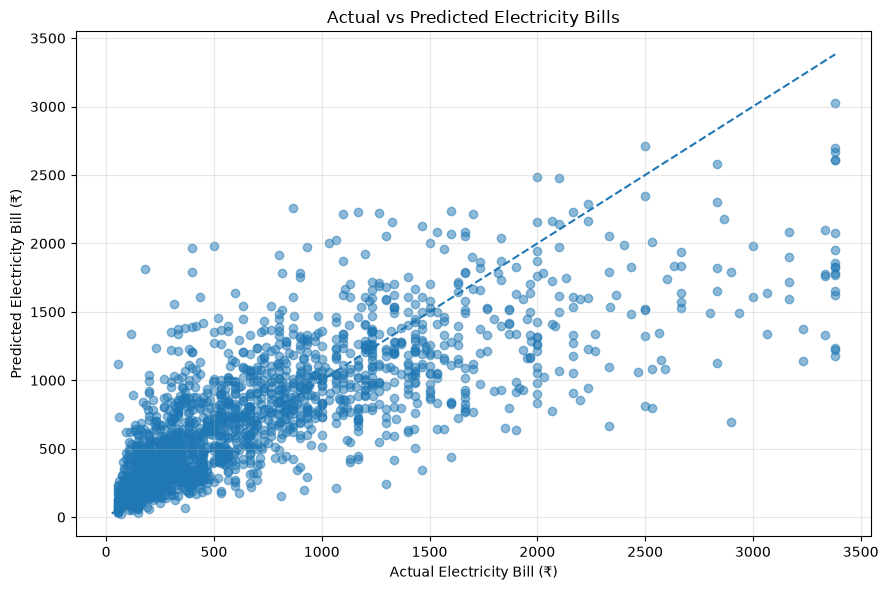

In [419]:
import matplotlib.pyplot as plt
import numpy as np

# Generate predictions for the complete test dataset
all_predictions = loaded_primary_model.predict(X_test_final_clean)

actual_values = np.asarray(y_test)

# Create Actual vs Predicted plot
plt.figure(figsize=(9, 6))

plt.scatter(
    actual_values,
    all_predictions,
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(actual_values.min(), all_predictions.min())
max_value = max(actual_values.max(), all_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Electricity Bill (₹)")
plt.ylabel("Predicted Electricity Bill (₹)")
plt.title("Actual vs Predicted Electricity Bills")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

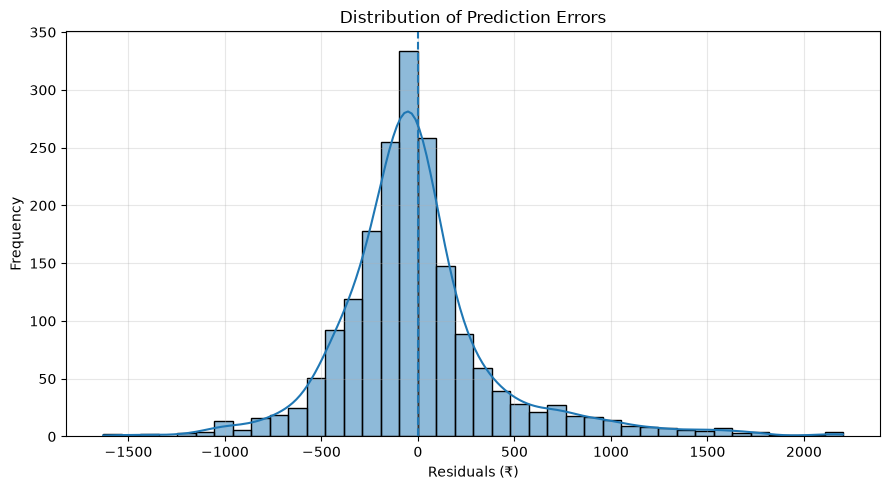

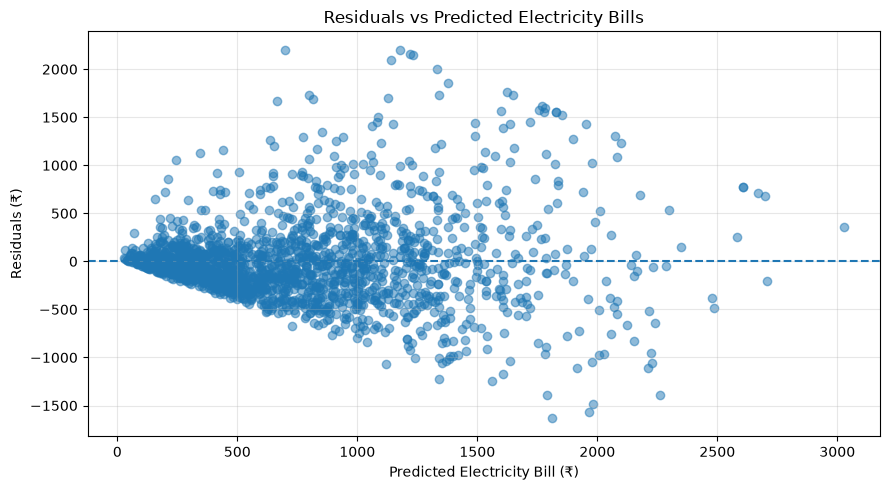

In [420]:
# Residual analysis

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Calculate residuals
residuals = actual_values - all_predictions

# Create residual distribution plot
plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.axvline(0, linestyle="--")

plt.xlabel("Residuals (₹)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Residuals vs predicted values
plt.figure(figsize=(9, 5))

plt.scatter(
    all_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Electricity Bill (₹)")
plt.ylabel("Residuals (₹)")
plt.title("Residuals vs Predicted Electricity Bills")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [421]:
# Quantify residual errors by prediction range

# Create residual analysis DataFrame
residual_df = pd.DataFrame({
    "Actual_Bill": actual_values,
    "Predicted_Bill": all_predictions,
    "Residual": residuals
})

# Divide households into four predicted bill groups
residual_df["Prediction_Range"] = pd.qcut(
    residual_df["Predicted_Bill"],
    q=4,
    duplicates="drop"
)

# Calculate error statistics for each group
residual_summary = residual_df.groupby(
    "Prediction_Range",
    observed=True
).agg(
    Households=("Actual_Bill", "size"),
    Average_Predicted=("Predicted_Bill", "mean"),
    Average_Actual=("Actual_Bill", "mean"),
    MAE=("Residual", lambda x: x.abs().mean()),
    Average_Residual=("Residual", "mean"),
    Residual_Std=("Residual", "std")
)

print("RESIDUAL ANALYSIS BY PREDICTED BILL RANGE")
print("-" * 85)

print(residual_summary.round(2).to_string())

RESIDUAL ANALYSIS BY PREDICTED BILL RANGE
-------------------------------------------------------------------------------------
                               Households  Average_Predicted  Average_Actual     MAE  Average_Residual  Residual_Std
Prediction_Range                                                                                                    
(26.238999999999997, 327.865]         474             211.41          217.70   92.30              6.28        140.02
(327.865, 645.023]                    473             475.11          410.45  201.90            -64.66        253.99
(645.023, 1026.548]                   473             831.32          818.04  332.49            -13.28        439.29
(1026.548, 3027.896]                  474            1433.46         1474.30  509.89             40.83        671.15


In [422]:
# Save the residual analysis results


residual_summary.to_csv(
    save_dir / "residual_analysis_by_prediction_range.csv",
    index=True
)

print("RESIDUAL ANALYSIS SAVED")
print("-" * 45)

print("File: residual_analysis_by_prediction_range.csv")
print("Location:", save_dir.resolve())

print("\nNumber of prediction groups:",
      len(residual_summary))

print("\nResidual analysis saved successfully!")

RESIDUAL ANALYSIS SAVED
---------------------------------------------
File: residual_analysis_by_prediction_range.csv
Location: C:\Users\Prithvi Vinayak P\Downloads\CEEW_ETL_Team_Package\CEEW_Energy_ETL\output\ml_preprocessed

Number of prediction groups: 4

Residual analysis saved successfully!


Advanced Feature Engineering

In [423]:
# Audit the excluded features

# 1. Identify previously excluded high-missingness features
missing_percentage = X_candidate.isna().mean() * 100

high_missing_features = missing_percentage[
    missing_percentage > 50
].index.tolist()

# 2. Create an audit summary
feature_audit = pd.DataFrame({
    "Feature": high_missing_features,
    "Missing_Percentage": [
        missing_percentage[col]
        for col in high_missing_features
    ],
    "Available_Values": [
        X_candidate[col].notna().sum()
        for col in high_missing_features
    ],
    "Unique_Values": [
        X_candidate[col].nunique()
        for col in high_missing_features
    ]
})

# 3. Sort by missing percentage
feature_audit = feature_audit.sort_values(
    by="Missing_Percentage",
    ascending=True
).reset_index(drop=True)

# 4. Display results
print("HIGH-MISSINGNESS FEATURE AUDIT")
print("-" * 75)

print("Total excluded features:", len(high_missing_features))

display(feature_audit.round(2))

# 5. Display features with at least 30% available observations
potential_candidates = feature_audit[
    feature_audit["Available_Values"] >= len(X_candidate) * 0.30
]

print("\nPOTENTIAL FEATURES FOR FURTHER INVESTIGATION")
print("-" * 65)

display(potential_candidates.round(2))

HIGH-MISSINGNESS FEATURE AUDIT
---------------------------------------------------------------------------
Total excluded features: 75


,Feature,Missing_Percentage,Available_Values,Unique_Values
0,q533_chulha_neg_health_yn,51.97,4548,2
1,q306_grid_rural_powercut_days_20,54.46,4312,11
2,q516_firewood_use_freq,56.91,4080,4
3,q314_b_online_pay_easy_diff,58.60,3920,2
4,q517_firewood_collect_purchase,58.87,3895,3
...,...,...,...,...
70,q608_a_ifprep_control_elec_exp,89.95,952,2
71,q406_noled_reason,89.99,948,6
72,q608_d_ifprep_elec_theft,90.22,926,2
73,q608_e_if_trust_increase,90.32,917,2



POTENTIAL FEATURES FOR FURTHER INVESTIGATION
-----------------------------------------------------------------


,Feature,Missing_Percentage,Available_Values,Unique_Values
0,q533_chulha_neg_health_yn,51.97,4548,2
1,q306_grid_rural_powercut_days_20,54.46,4312,11
2,q516_firewood_use_freq,56.91,4080,4
3,q314_b_online_pay_easy_diff,58.60,3920,2
4,q517_firewood_collect_purchase,58.87,3895,3
5,q467_fridge_no,59.59,3826,3
6,q470_fridge_off_time,59.59,3826,6
7,q468_fridge_most_yrs,59.87,3800,28
8,q501_png_use_yn,62.21,3578,2
9,q205_priminc_earner_age,62.87,3516,63


In [424]:
# Investigate conditional missing values

# Check conditional missingness of potential features

conditional_checks = {
    "Refrigerator details": {
        "parent": "q466_fridge_yn",
        "children": [
            "q467_fridge_no",
            "q468_fridge_most_yrs",
            "q469_fridge_most_bee_star",
            "q470_fridge_off_time"
        ]
    },
    "Online payment difficulty": {
        "parent": "q314_a_online_pay_ever_yn",
        "children": [
            "q314_b_online_pay_easy_diff"
        ]
    },
    "Rural electricity interruptions": {
        "parent": "survey_type_code",
        "children": [
            "q306_grid_rural_powercut_days_20"
        ]
    }
}

for group_name, details in conditional_checks.items():

    parent = details["parent"]

    if parent not in X_candidate.columns:
        print(f"\n{group_name}: Parent column not found.")
        continue

    children = [
        col for col in details["children"]
        if col in X_candidate.columns
    ]

    print("\n" + "=" * 65)
    print(group_name.upper())
    print("=" * 65)

    for child in children:

        result = X_candidate.groupby(
            parent,
            dropna=False
        )[child].agg(
            Total="count"
        )

        missing_counts = X_candidate.groupby(
            parent,
            dropna=False
        )[child].apply(
            lambda x: x.isna().sum()
        )

        total_counts = X_candidate.groupby(
            parent,
            dropna=False
        )[child].size()

        result["Missing"] = missing_counts
        result["Total_Rows"] = total_counts

        result["Missing_Percentage"] = (
            result["Missing"] / result["Total_Rows"] * 100
        )

        print(f"\nFeature: {child}")
        display(result.round(2))


REFRIGERATOR DETAILS

Feature: q467_fridge_no


,Total,Missing,Total_Rows,Missing_Percentage
q466_fridge_yn,,,,
0.0,0,5643,5643,100.0
1.0,3826,0,3826,0.0



Feature: q468_fridge_most_yrs


,Total,Missing,Total_Rows,Missing_Percentage
q466_fridge_yn,,,,
0.0,0,5643,5643,100.00
1.0,3800,26,3826,0.68



Feature: q469_fridge_most_bee_star


,Total,Missing,Total_Rows,Missing_Percentage
q466_fridge_yn,,,,
0.0,0,5643,5643,100.00
1.0,2980,846,3826,22.11


... (2 outputs left out)


ONLINE PAYMENT DIFFICULTY

Feature: q314_b_online_pay_easy_diff


,Total,Missing,Total_Rows,Missing_Percentage
q314_a_online_pay_ever_yn,,,,
0.0,3912,3074,6986,44.00
1.0,0,818,818,100.00
NaN,8,1657,1665,99.52



RURAL ELECTRICITY INTERRUPTIONS

Feature: q306_grid_rural_powercut_days_20


,Total,Missing,Total_Rows,Missing_Percentage
survey_type_code,,,,
1,4312,1579,5891,26.8
2,0,3578,3578,100.0


In [425]:
# Correctly investigate online payment

# Online payment conditional missingness audit

online_cols = [
    "q314_pay_online_1",
    "q314_a_online_pay_ever_yn",
    "q314_b_online_pay_easy_diff"
]

# Display value counts
print("ONLINE PAYMENT VARIABLE DISTRIBUTIONS")
print("-" * 65)

for col in online_cols:
    print(f"\n{col}")
    display(
        X_candidate[col].value_counts(dropna=False).sort_index()
    )

# Check the relationship between the three variables
online_audit = X_candidate.groupby(
    [
        "q314_pay_online_1",
        "q314_a_online_pay_ever_yn"
    ],
    dropna=False
).agg(
    Total_Rows=("q314_b_online_pay_easy_diff", "size"),
    Answered=("q314_b_online_pay_easy_diff", "count"),
    Missing=("q314_b_online_pay_easy_diff",
             lambda x: x.isna().sum())
).reset_index()

online_audit["Missing_Percentage"] = (
    online_audit["Missing"] /
    online_audit["Total_Rows"] * 100
)

print("\nCONDITIONAL ONLINE PAYMENT AUDIT")
print("-" * 75)

display(online_audit.round(2))

ONLINE PAYMENT VARIABLE DISTRIBUTIONS
-----------------------------------------------------------------

q314_pay_online_1


q314_pay_online_1
0.0    7804
1.0    1665
Name: count, dtype: int64


q314_a_online_pay_ever_yn


q314_a_online_pay_ever_yn
0.0    6986
1.0     818
NaN    1665
Name: count, dtype: int64


q314_b_online_pay_easy_diff


q314_b_online_pay_easy_diff
1.0    1855
2.0    2065
NaN    5549
Name: count, dtype: int64


CONDITIONAL ONLINE PAYMENT AUDIT
---------------------------------------------------------------------------


,q314_pay_online_1,q314_a_online_pay_ever_yn,Total_Rows,Answered,Missing,Missing_Percentage
0,0.0,0.0,6986,3912,3074,44.00
1,0.0,1.0,818,0,818,100.00
2,1.0,NaN,1665,8,1657,99.52


In [426]:
# Inspect the eligible responses

# 1. Identify households eligible for Q314b
eligible_online = (
    X_candidate["q314_pay_online_1"].eq(0)
    & X_candidate["q314_a_online_pay_ever_yn"].eq(0)
)

# 2. Extract the eligible Q314b responses
online_feature = X_candidate.loc[
    eligible_online,
    "q314_b_online_pay_easy_diff"
]

print("ONLINE PAYMENT FEATURE ANALYSIS")
print("-" * 55)

print("Eligible households:", len(online_feature))
print("Answered:", online_feature.notna().sum())
print("Missing:", online_feature.isna().sum())

print("\nResponse distribution:")
print(online_feature.value_counts(dropna=False).sort_index())

print("\nMissing percentage:",
      round(online_feature.isna().mean() * 100, 2), "%")


# 3. Check the eight unexpected responses
unexpected = (
    X_candidate["q314_pay_online_1"].eq(1)
    & X_candidate["q314_b_online_pay_easy_diff"].notna()
)

print("\nUnexpected non-missing responses:", unexpected.sum())

print("\nTheir Q314b values:")
print(
    X_candidate.loc[
        unexpected,
        "q314_b_online_pay_easy_diff"
    ].value_counts()
)

ONLINE PAYMENT FEATURE ANALYSIS
-------------------------------------------------------
Eligible households: 6986
Answered: 3912
Missing: 3074

Response distribution:
q314_b_online_pay_easy_diff
1.0    1847
2.0    2065
NaN    3074
Name: count, dtype: int64

Missing percentage: 44.0 %

Unexpected non-missing responses: 8

Their Q314b values:
q314_b_online_pay_easy_diff
1.0    8
Name: count, dtype: int64


In [427]:
# Create the engineered feature

# Create a separate dataset for feature engineering
X_enhanced_candidate = X_candidate.copy()

# Create the new online payment status feature
def classify_online_payment(row):

    current = row["q314_pay_online_1"]
    previous = row["q314_a_online_pay_ever_yn"]
    response = row["q314_b_online_pay_easy_diff"]

    # Currently pays online
    if current == 1:
        if pd.notna(response):
            return "inconsistent_response"
        return "currently_pays_online"

    # Does not currently pay online
    if current == 0:

        if previous == 1:
            return "previously_paid_online"

        if previous == 0:
            if pd.isna(response):
                return "eligible_no_response"

            return f"response_code_{int(response)}"

    return "unknown_or_missing_status"


# Apply the classification
X_enhanced_candidate["online_payment_status"] = (
    X_enhanced_candidate.apply(
        classify_online_payment,
        axis=1
    )
)

# Display category counts
print("ENGINEERED ONLINE PAYMENT FEATURE")
print("-" * 60)

print(
    X_enhanced_candidate["online_payment_status"]
    .value_counts(dropna=False)
)

print("\nTotal households:",
      len(X_enhanced_candidate))

print("\nMissing values:",
      X_enhanced_candidate["online_payment_status"].isna().sum())

ENGINEERED ONLINE PAYMENT FEATURE
------------------------------------------------------------
online_payment_status
eligible_no_response      3074
response_code_2           2065
response_code_1           1847
currently_pays_online     1657
previously_paid_online     818
inconsistent_response        8
Name: count, dtype: int64

Total households: 9469

Missing values: 0


In [428]:
# Engineer refrigerator and power-cut features

# Create refrigerator and electricity reliability features

# 1. Refrigerator ownership indicator
X_enhanced_candidate["fridge_owned"] = (
    X_enhanced_candidate["q466_fridge_yn"]
)

# 2. Refrigerator count
X_enhanced_candidate["fridge_count"] = (
    X_enhanced_candidate["q467_fridge_no"]
    .fillna(0)
)

# 3. Refrigerator age
# Keep missing values for non-owners and unanswered responses
X_enhanced_candidate["fridge_age_years"] = (
    X_enhanced_candidate["q468_fridge_most_yrs"]
)

# 4. Refrigerator energy-star rating
X_enhanced_candidate["fridge_bee_rating"] = (
    X_enhanced_candidate["q469_fridge_most_bee_star"]
)

# 5. Refrigerator off-time
X_enhanced_candidate["fridge_off_time"] = (
    X_enhanced_candidate["q470_fridge_off_time"]
)

# 6. Identify rural households
is_rural = X_enhanced_candidate["survey_type_code"].eq(1)

# 7. Create applicability indicator
X_enhanced_candidate["rural_powercut_applicable"] = (
    is_rural.astype(int)
)

# 8. Recover rural power-cut information
X_enhanced_candidate["rural_powercut_days"] = (
    X_enhanced_candidate["q306_grid_rural_powercut_days_20"]
)

# Urban households are not eligible for this question
X_enhanced_candidate.loc[
    ~is_rural,
    "rural_powercut_days"
] = 0

# 9. Display results
new_features = [
    "online_payment_status",
    "fridge_owned",
    "fridge_count",
    "fridge_age_years",
    "fridge_bee_rating",
    "fridge_off_time",
    "rural_powercut_applicable",
    "rural_powercut_days"
]

print("ENGINEERED FEATURE SUMMARY")
print("-" * 65)

for col in new_features:
    print(f"\n{col}")
    print("Missing:", X_enhanced_candidate[col].isna().sum())
    print("Unique values:", X_enhanced_candidate[col].nunique())

ENGINEERED FEATURE SUMMARY
-----------------------------------------------------------------

online_payment_status
Missing: 0
Unique values: 6

fridge_owned
Missing: 0
Unique values: 2

fridge_count
Missing: 0
Unique values: 4

fridge_age_years
Missing: 5669
Unique values: 28

fridge_bee_rating
Missing: 6489
Unique values: 6

fridge_off_time
Missing: 5643
Unique values: 6

rural_powercut_applicable
Missing: 0
Unique values: 2

rural_powercut_days
Missing: 1579
Unique values: 11


In [429]:
# Investigate firewood-related features

# Firewood feature audit

firewood_cols = [
    "q516_firewood_use_freq",
    "q517_firewood_collect_purchase",
    "q517_a_firewood_collect_who",
    "q517_b_firewood_collect_freq"
]

print("FIREWOOD FEATURE DISTRIBUTIONS")
print("-" * 65)

for col in firewood_cols:

    print(f"\n{col}")

    print("Missing values:",
          X_enhanced_candidate[col].isna().sum())

    print("\nValue counts:")

    display(
        X_enhanced_candidate[col]
        .value_counts(dropna=False)
        .sort_index()
    )

FIREWOOD FEATURE DISTRIBUTIONS
-----------------------------------------------------------------

q516_firewood_use_freq
Missing values: 5389

Value counts:


q516_firewood_use_freq
1.0    2155
2.0    1081
3.0     659
4.0     185
NaN    5389
Name: count, dtype: int64


q517_firewood_collect_purchase
Missing values: 5574

Value counts:


q517_firewood_collect_purchase
1.0    3132
2.0     426
3.0     337
NaN    5574
Name: count, dtype: int64


q517_a_firewood_collect_who
Missing values: 6000

Value counts:


q517_a_firewood_collect_who
1.0    1558
2.0    1086
3.0     825
NaN    6000
Name: count, dtype: int64


q517_b_firewood_collect_freq
Missing values: 6560

Value counts:


q517_b_firewood_collect_freq
1.0     501
2.0    1360
3.0     842
4.0     206
NaN    6560
Name: count, dtype: int64

In [430]:
# Check the parent cooking-fuel variable

print("Cooking fuel distribution:")

print(
    X_enhanced_candidate["q529_prim_cook_fuel"]
    .value_counts(dropna=False)
    .sort_index()
)

Cooking fuel distribution:
q529_prim_cook_fuel
1     7274
2       36
4     1602
5      158
6      338
7       42
8       12
10       7
Name: count, dtype: int64


In [431]:
# Compare cooking fuel with firewood usage

pd.crosstab(
    X_enhanced_candidate["q529_prim_cook_fuel"],
    X_enhanced_candidate["q516_firewood_use_freq"],
    margins=True,
    dropna=False
)

q516_firewood_use_freq,1.0,2.0,3.0,4.0,NaN,All
q529_prim_cook_fuel,,,,,,
1,749,785,497,110,5133,7274
2,0,0,0,0,36,36
4,1175,244,133,50,0,1602
5,93,19,5,16,25,158
6,131,28,8,7,164,338
7,6,4,15,2,15,42
8,1,1,1,0,9,12
10,0,0,0,0,7,7
All,2155,1081,659,185,5389,9469


In [432]:
# Check the relationship with other firewood questions

firewood_cols = [
    "q517_firewood_collect_purchase",
    "q517_a_firewood_collect_who",
    "q517_b_firewood_collect_freq"
]

for col in firewood_cols:
    print("\n", col)

    display(pd.crosstab(
        X_enhanced_candidate["q529_prim_cook_fuel"],
        X_enhanced_candidate[col],
        margins=True,
        dropna=False
    ))


 q517_firewood_collect_purchase


q517_firewood_collect_purchase,1.0,2.0,3.0,NaN,All
q529_prim_cook_fuel,,,,,
1,1665,242,124,5243,7274
2,0,0,0,36,36
4,1207,155,190,50,1602
5,106,7,4,41,158
6,137,16,14,171,338
7,15,5,5,17,42
8,2,1,0,9,12
10,0,0,0,7,7
All,3132,426,337,5574,9469



 q517_a_firewood_collect_who


q517_a_firewood_collect_who,1.0,2.0,3.0,NaN,All
q529_prim_cook_fuel,,,,,
1,874,515,400,5485,7274
2,0,0,0,36,36
4,584,465,348,205,1602
5,29,38,43,48,158
6,69,65,17,187,338
7,1,2,17,22,42
8,1,1,0,10,12
10,0,0,0,7,7
All,1558,1086,825,6000,9469



 q517_b_firewood_collect_freq


q517_b_firewood_collect_freq,1.0,2.0,3.0,4.0,NaN,All
q529_prim_cook_fuel,,,,,,
1,193,620,441,116,5904,7274
2,0,0,0,0,36,36
4,226,641,344,72,319,1602
5,32,35,26,12,53,158
6,49,60,28,6,195,338
7,0,3,3,0,36,42
8,1,1,0,0,10,12
10,0,0,0,0,7,7
All,501,1360,842,206,6560,9469


## Advanced Feature Engineering – Validation Experiment

The next cells add a small set of features from the conditional-missingness audits. They preserve the original baseline cells and use the existing training/validation split.

Important decisions:
- Firewood response codes are kept as categories (`code_1`, `code_2`, etc.). Their labels are not assumed.
- Missing firewood responses are kept as a separate `not_reported` category. They are **not** treated as proof that a household does not use firewood.
- Refrigerator details are handled using the ownership audit: non-owners receive zero fridge count/age, while missing values among owners remain missing.
- Urban households receive zero for the rural-only power-cut question; missing answers among rural households remain missing.
- The comparison uses the existing validation split. Do not use the test set for this experiment.


In [433]:
# Create additional features for the advanced experiment

import numpy as np
import pandas as pd

# Confirm that all required source columns are available
required_columns = [
    "q314_pay_online_1",
    "q314_a_online_pay_ever_yn",
    "q314_b_online_pay_easy_diff",
    "q466_fridge_yn",
    "q467_fridge_no",
    "q468_fridge_most_yrs",
    "q469_fridge_most_bee_star",
    "q470_fridge_off_time",
    "survey_type_code",
    "q306_grid_rural_powercut_days_20",
    "q516_firewood_use_freq",
    "q517_firewood_collect_purchase",
    "q517_a_firewood_collect_who",
    "q517_b_firewood_collect_freq"
]

missing_required = [
    col for col in required_columns
    if col not in X_enhanced_candidate.columns
]

if missing_required:
    raise KeyError(f"Required source columns are missing: {missing_required}")


# Convert numeric survey codes into text categories.
# This avoids assuming that the numeric codes have an ordinal meaning.
def code_as_category(series):
    return series.map(
        lambda value: (
            "not_reported"
            if pd.isna(value)
            else f"code_{int(value)}"
        )
    )


# 1. Refrigerator features
is_fridge_owner = X_enhanced_candidate["q466_fridge_yn"].eq(1)

# The ownership audit showed that non-owners have no refrigerator count.
X_enhanced_candidate["fridge_count_experiment"] = (
    X_enhanced_candidate["q467_fridge_no"].fillna(0)
)

# Set age to zero only for households that do not own a refrigerator.
# Keep the 26 missing owner responses as missing.
X_enhanced_candidate["fridge_age_experiment"] = (
    X_enhanced_candidate["q468_fridge_most_yrs"].where(
        is_fridge_owner,
        0
    )
)


# Make refrigerator codes categorical while separating:
# - no refrigerator
# - owner but response not reported
# - an observed survey code
def conditional_code_category(values, applicable):
    result = []

    for value, is_applicable in zip(values, applicable):
        if not is_applicable:
            result.append("not_applicable")
        elif pd.isna(value):
            result.append("not_reported")
        else:
            result.append(f"code_{int(value)}")

    return pd.Series(result, index=values.index, dtype="object")


X_enhanced_candidate["fridge_bee_status_experiment"] = (
    conditional_code_category(
        X_enhanced_candidate["q469_fridge_most_bee_star"],
        is_fridge_owner
    )
)

X_enhanced_candidate["fridge_off_time_status_experiment"] = (
    conditional_code_category(
        X_enhanced_candidate["q470_fridge_off_time"],
        is_fridge_owner
    )
)


# 2. Rural electricity interruption feature
is_rural = X_enhanced_candidate["survey_type_code"].eq(1)

X_enhanced_candidate["rural_powercut_days_experiment"] = (
    X_enhanced_candidate["q306_grid_rural_powercut_days_20"]
)

# The question is not applicable to urban households.
# Keep unanswered rural responses as missing.
X_enhanced_candidate.loc[
    ~is_rural,
    "rural_powercut_days_experiment"
] = 0


# 3. Firewood features
# Keep the original response codes as categories.
# Missing responses remain a separate category, not an assumed "no use".
firewood_source_cols = {
    "q516_firewood_use_freq": "firewood_use_frequency_experiment",
    "q517_firewood_collect_purchase": "firewood_collect_purchase_experiment",
    "q517_a_firewood_collect_who": "firewood_collect_who_experiment",
    "q517_b_firewood_collect_freq": "firewood_collect_frequency_experiment"
}

for source_col, new_col in firewood_source_cols.items():
    X_enhanced_candidate[new_col] = code_as_category(
        X_enhanced_candidate[source_col]
    )


# 4. Build a summary of the new features
experiment_categorical_features = [
    "online_payment_status",
    "fridge_bee_status_experiment",
    "fridge_off_time_status_experiment",
    "firewood_use_frequency_experiment",
    "firewood_collect_purchase_experiment",
    "firewood_collect_who_experiment",
    "firewood_collect_frequency_experiment"
]

experiment_numeric_features = [
    "fridge_count_experiment",
    "fridge_age_experiment",
    "rural_powercut_days_experiment"
]

new_feature_summary = []

for col in experiment_categorical_features + experiment_numeric_features:
    new_feature_summary.append({
        "Feature": col,
        "Type": (
            "Categorical"
            if col in experiment_categorical_features
            else "Numerical"
        ),
        "Missing": X_enhanced_candidate[col].isna().sum(),
        "Unique_Values": X_enhanced_candidate[col].nunique()
    })

new_feature_summary = pd.DataFrame(new_feature_summary)

print("ADVANCED FEATURE ENGINEERING SUMMARY")
print("-" * 65)
display(new_feature_summary)

print("\nTotal engineered features:",
      len(experiment_categorical_features) + len(experiment_numeric_features))


ADVANCED FEATURE ENGINEERING SUMMARY
-----------------------------------------------------------------


,Feature,Type,Missing,Unique_Values
0,online_payment_status,Categorical,0,6
1,fridge_bee_status_experiment,Categorical,0,8
2,fridge_off_time_status_experiment,Categorical,0,7
3,firewood_use_frequency_experiment,Categorical,0,5
4,firewood_collect_purchase_experiment,Categorical,0,4
5,firewood_collect_who_experiment,Categorical,0,4
6,firewood_collect_frequency_experiment,Categorical,0,5
7,fridge_count_experiment,Numerical,0,4
8,fridge_age_experiment,Numerical,26,28
9,rural_powercut_days_experiment,Numerical,1579,11



Total engineered features: 10


### Train and compare the enhanced model

This cell aligns the engineered features to the **same** `X_fit_clean` and `X_valid_clean` rows used by the baseline. It clones the existing HistGradientBoosting model and fits a separate preprocessing pipeline. The baseline model and saved artifacts are not overwritten.


In [434]:
# Compare the baseline and advanced-feature models on validation data

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# New feature names
new_categorical_features = experiment_categorical_features.copy()
new_numeric_features = experiment_numeric_features.copy()

new_feature_columns = (
    new_categorical_features
    + new_numeric_features
)

# Make sure the engineered features are not already in the baseline data
overlap = [
    col for col in new_feature_columns
    if col in X_fit_clean.columns
]

if overlap:
    raise ValueError(
        f"These engineered features already exist in the baseline data: {overlap}"
    )

# Align engineered rows using the original row indexes.
# This guarantees the same train/validation households as the baseline.
X_fit_enhanced = X_fit_clean.copy()
X_valid_enhanced = X_valid_clean.copy()

X_fit_enhanced[new_feature_columns] = (
    X_enhanced_candidate.loc[
        X_fit_enhanced.index,
        new_feature_columns
    ]
)

X_valid_enhanced[new_feature_columns] = (
    X_enhanced_candidate.loc[
        X_valid_enhanced.index,
        new_feature_columns
    ]
)

# Check that the feature rows and target rows are aligned
assert X_fit_enhanced.index.equals(y_fit.index)
assert X_valid_enhanced.index.equals(y_valid.index)

# Extend the original feature-type lists
categorical_features_enhanced = (
    categorical_cols_clean + new_categorical_features
)

numeric_features_enhanced = (
    numeric_cols_clean + new_numeric_features
)

# Create preprocessing steps for the enhanced dataset
numeric_transformer_enhanced = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_enhanced = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

enhanced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer_enhanced,
            numeric_features_enhanced
        ),
        (
            "cat",
            categorical_transformer_enhanced,
            categorical_features_enhanced
        )
    ],
    sparse_threshold=0
)

# Reuse the same HistGradientBoosting settings as the baseline model.
enhanced_hgb_model = clone(
    clean_hgb_pipeline.named_steps["model"]
)

# Create a separate experiment pipeline
enhanced_hgb_pipeline = Pipeline(steps=[
    ("preprocessor", enhanced_preprocessor),
    ("model", enhanced_hgb_model)
])

# Train only on the existing fitting data
enhanced_hgb_pipeline.fit(
    X_fit_enhanced,
    y_fit
)

# Generate validation predictions
baseline_validation_predictions = clean_hgb_pipeline.predict(
    X_valid_clean
)

enhanced_validation_predictions = enhanced_hgb_pipeline.predict(
    X_valid_enhanced
)

# Compare both models using the same validation households
comparison_results = pd.DataFrame({
    "Model": [
        "Baseline HGB",
        "Advanced Feature HGB"
    ],
    "MAE": [
        mean_absolute_error(y_valid, baseline_validation_predictions),
        mean_absolute_error(y_valid, enhanced_validation_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_valid, baseline_validation_predictions)),
        np.sqrt(mean_squared_error(y_valid, enhanced_validation_predictions))
    ],
    "R2 Score": [
        r2_score(y_valid, baseline_validation_predictions),
        r2_score(y_valid, enhanced_validation_predictions)
    ]
})

print("BASELINE VS ADVANCED FEATURE MODEL")
print("-" * 70)
display(comparison_results.round(3))

mae_change = (
    comparison_results.loc[1, "MAE"]
    - comparison_results.loc[0, "MAE"]
)

print("\nChange in validation MAE:",
      round(mae_change, 3))

if mae_change < 0:
    print("The advanced-feature model has a lower validation MAE.")
elif mae_change > 0:
    print("The advanced-feature model has a higher validation MAE.")
else:
    print("Both models have the same validation MAE.")

print("\nBaseline feature count:", X_fit_clean.shape[1])
print("Advanced feature count:", X_fit_enhanced.shape[1])
print("Validation households:", len(y_valid))

print("\nNote: The test set has not been used in this comparison.")


BASELINE VS ADVANCED FEATURE MODEL
----------------------------------------------------------------------


,Model,MAE,RMSE,R2 Score
0,Baseline HGB,291.096,442.551,0.568
1,Advanced Feature HGB,289.800,440.223,0.572



Change in validation MAE: -1.296
The advanced-feature model has a lower validation MAE.

Baseline feature count: 211
Advanced feature count: 221
Validation households: 1515

Note: The test set has not been used in this comparison.


### Identify which engineered feature groups are helping

The full advanced-feature model improved validation MAE only slightly. Before adding more features, this experiment tests each group separately:
- Online payment
- Refrigerator
- Rural power cuts
- Firewood

Each model uses the same fitting and validation households, the same baseline HistGradientBoosting settings, and a separate preprocessing pipeline. The test set is not used. A negative change in MAE means the feature group improved validation MAE compared with the baseline.


In [435]:
# Compare the contribution of each engineered feature group

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define the engineered feature groups
feature_groups = {
    "Online payment": [
        "online_payment_status"
    ],
    "Refrigerator": [
        "fridge_bee_status_experiment",
        "fridge_off_time_status_experiment",
        "fridge_count_experiment",
        "fridge_age_experiment"
    ],
    "Rural power cuts": [
        "rural_powercut_days_experiment"
    ],
    "Firewood": [
        "firewood_use_frequency_experiment",
        "firewood_collect_purchase_experiment",
        "firewood_collect_who_experiment",
        "firewood_collect_frequency_experiment"
    ],
    "All engineered features": new_feature_columns
}

# Calculate baseline validation metrics
baseline_predictions_for_ablation = clean_hgb_pipeline.predict(X_valid_clean)
baseline_mae_for_ablation = mean_absolute_error(
    y_valid, baseline_predictions_for_ablation
)

baseline_rmse_for_ablation = np.sqrt(mean_squared_error(
    y_valid, baseline_predictions_for_ablation
))

baseline_r2_for_ablation = r2_score(
    y_valid, baseline_predictions_for_ablation
)

results_by_group = [{
    "Feature group": "Baseline (no new features)",
    "Added features": 0,
    "MAE": baseline_mae_for_ablation,
    "RMSE": baseline_rmse_for_ablation,
    "R2 Score": baseline_r2_for_ablation,
    "MAE change vs baseline": 0.0
}]

# Train one separate model for each feature group
for group_name, selected_features in feature_groups.items():

    # Confirm the engineered features exist
    missing_features = [
        col for col in selected_features
        if col not in X_enhanced_candidate.columns
    ]

    if missing_features:
        raise KeyError(
            f"Missing engineered features for {group_name}: {missing_features}"
        )

    # Add this group's features to the same baseline fitting/validation rows
    X_fit_group = X_fit_clean.copy()
    X_valid_group = X_valid_clean.copy()

    X_fit_group[selected_features] = X_enhanced_candidate.loc[
        X_fit_group.index, selected_features
    ]

    X_valid_group[selected_features] = X_enhanced_candidate.loc[
        X_valid_group.index, selected_features
    ]

    # Identify which added columns are categorical and numerical
    added_categorical = [
        col for col in selected_features
        if col in experiment_categorical_features
    ]

    added_numeric = [
        col for col in selected_features
        if col in experiment_numeric_features
    ]

    # Build preprocessing using only the selected group plus baseline features
    numeric_transformer_group = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_transformer_group = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor_group = ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_transformer_group,
                numeric_cols_clean + added_numeric
            ),
            (
                "cat",
                categorical_transformer_group,
                categorical_cols_clean + added_categorical
            )
        ],
        sparse_threshold=0
    )

    # Use the same HistGradientBoosting settings as the baseline
    model_group = clone(clean_hgb_pipeline.named_steps["model"])

    pipeline_group = Pipeline(steps=[
        ("preprocessor", preprocessor_group),
        ("model", model_group)
    ])

    pipeline_group.fit(X_fit_group, y_fit)

    group_predictions = pipeline_group.predict(X_valid_group)

    group_mae = mean_absolute_error(y_valid, group_predictions)
    group_rmse = np.sqrt(mean_squared_error(y_valid, group_predictions))
    group_r2 = r2_score(y_valid, group_predictions)

    results_by_group.append({
        "Feature group": group_name,
        "Added features": len(selected_features),
        "MAE": group_mae,
        "RMSE": group_rmse,
        "R2 Score": group_r2,
        "MAE change vs baseline": group_mae - baseline_mae_for_ablation
    })

# Display results; a negative MAE change indicates improvement
feature_group_comparison = pd.DataFrame(results_by_group)

print("FEATURE GROUP ABLATION — VALIDATION RESULTS")
print("-" * 75)
display(
    feature_group_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

print("\nValidation households:", len(y_valid))
print("Test set used: No")
print("\nInterpretation: compare each group with the baseline row.")
print("A lower MAE is better; a negative MAE change means improvement.")


FEATURE GROUP ABLATION — VALIDATION RESULTS
---------------------------------------------------------------------------


,Feature group,Added features,MAE,RMSE,R2 Score,MAE change vs baseline
0,Refrigerator,4,288.705,441.552,0.570,-2.392
1,All engineered features,10,289.800,440.223,0.572,-1.296
2,Online payment,1,290.513,443.326,0.566,-0.583
3,Rural power cuts,1,290.815,442.292,0.568,-0.281
4,Baseline (no new features),0,291.096,442.551,0.568,0.000
5,Firewood,4,291.237,442.373,0.568,0.140



Validation households: 1515
Test set used: No

Interpretation: compare each group with the baseline row.
A lower MAE is better; a negative MAE change means improvement.


## Cross-validation: confirm the useful engineered features

The feature-group experiment showed small improvements on one validation split. This section checks whether those improvements are consistent across **five folds** of the training data.

We compare three candidates:

1. Baseline features (no engineered features)
2. Baseline + refrigerator features
3. Baseline + all 10 engineered features

The original test set is not used. Imputation and one-hot encoding are fitted separately inside each fold, so each fold's held-out rows do not influence preprocessing.

In [436]:
# Compare feature sets using 5-fold cross-validation on training data only

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare the training data used for cross-validation.
# The original test set is deliberately excluded.
X_cv_baseline = X_train_final_clean.copy()
y_cv = y_train.loc[X_cv_baseline.index].copy()

# Confirm that all rows and engineered features line up correctly.
assert X_cv_baseline.index.equals(y_cv.index)
assert X_cv_baseline.index.isin(X_enhanced_candidate.index).all()

# 2. Define the three feature sets to compare.
refrigerator_features_cv = [
    "fridge_bee_status_experiment",
    "fridge_off_time_status_experiment",
    "fridge_count_experiment",
    "fridge_age_experiment"
]

cv_feature_sets = {
    "Baseline": [],
    "Refrigerator only": refrigerator_features_cv,
    "All engineered features": new_feature_columns
}

# 3. Set up the same 5 folds for every feature set.
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_fold_results = []

# 4. Train and evaluate each feature set across the same folds.
for feature_set_name, added_features in cv_feature_sets.items():

    X_cv = X_cv_baseline.copy()

    if added_features:
        missing_features = [
            col for col in added_features
            if col not in X_enhanced_candidate.columns
        ]
        if missing_features:
            raise KeyError(
                f"Missing engineered features: {missing_features}"
            )

        X_cv[added_features] = X_enhanced_candidate.loc[
            X_cv.index,
            added_features
        ]

    # Add the selected engineered columns to the proper feature-type lists.
    added_categorical = [
        col for col in added_features
        if col in experiment_categorical_features
    ]
    added_numeric = [
        col for col in added_features
        if col in experiment_numeric_features
    ]

    cv_categorical_columns = (
        categorical_cols_clean + added_categorical
    )
    cv_numeric_columns = (
        numeric_cols_clean + added_numeric
    )

    # Check that every column is included exactly once.
    if len(cv_categorical_columns) != len(set(cv_categorical_columns)):
        raise ValueError("Duplicate categorical columns found.")
    if len(cv_numeric_columns) != len(set(cv_numeric_columns)):
        raise ValueError("Duplicate numerical columns found.")

    # Use the same preprocessing approach as the baseline pipeline.
    # These imputers and encoders are fitted within each fold only.
    cv_preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="median"))
                ]),
                cv_numeric_columns
            ),
            (
                "cat",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]),
                cv_categorical_columns
            )
        ],
        sparse_threshold=0
    )

    for fold_number, (train_index, valid_index) in enumerate(
        cv.split(X_cv), start=1
    ):
        X_fold_train = X_cv.iloc[train_index]
        X_fold_valid = X_cv.iloc[valid_index]
        y_fold_train = y_cv.iloc[train_index]
        y_fold_valid = y_cv.iloc[valid_index]

        # Clone the previously selected HistGradientBoosting settings.
        fold_pipeline = Pipeline(steps=[
            ("preprocessor", clone(cv_preprocessor)),
            ("model", clone(clean_hgb_pipeline.named_steps["model"]))
        ])

        fold_pipeline.fit(X_fold_train, y_fold_train)
        fold_predictions = fold_pipeline.predict(X_fold_valid)

        cv_fold_results.append({
            "Feature set": feature_set_name,
            "Fold": fold_number,
            "MAE": mean_absolute_error(
                y_fold_valid, fold_predictions
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y_fold_valid, fold_predictions
            )),
            "R2 Score": r2_score(
                y_fold_valid, fold_predictions
            )
        })

# 5. Display fold-level results.
cv_fold_results_df = pd.DataFrame(cv_fold_results)

print("FIVE-FOLD CROSS-VALIDATION — FOLD RESULTS")
print("-" * 75)
display(cv_fold_results_df.round(3))

# 6. Summarize the mean and standard deviation across folds.
cv_summary = (
    cv_fold_results_df
    .groupby("Feature set")
    .agg(
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        RMSE_Mean=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std"),
        R2_Mean=("R2 Score", "mean"),
        R2_Std=("R2 Score", "std")
    )
    .reset_index()
    .sort_values("MAE_Mean")
    .reset_index(drop=True)
)

print("\nFIVE-FOLD CROSS-VALIDATION — SUMMARY")
print("-" * 75)
display(cv_summary.round(3))

# 7. Show the candidate with the lowest average MAE.
best_cv_candidate = cv_summary.iloc[0]

print("\nLowest average CV MAE:", best_cv_candidate["Feature set"])
print("Average MAE:", round(best_cv_candidate["MAE_Mean"], 3))
print("MAE standard deviation:", round(best_cv_candidate["MAE_Std"], 3))

print("\nTraining households used:", len(y_cv))
print("Number of folds:", cv.get_n_splits())
print("Test set used: No")
print("\nLower MAE and RMSE are better; higher R2 is better.")
print("A smaller standard deviation means the fold scores varied less.")

# 8. Save the cross-validation results beside the existing ML outputs.
if "save_dir" in globals():
    save_dir.mkdir(parents=True, exist_ok=True)
    cv_fold_results_df.to_csv(
        save_dir / "feature_group_cross_validation_folds.csv",
        index=False
    )
    cv_summary.to_csv(
        save_dir / "feature_group_cross_validation_summary.csv",
        index=False
    )
    print("\nCross-validation result files saved to:")
    print(save_dir.resolve())
else:
    print("\nThe save_dir variable was not found; results are displayed above but were not saved.")

FIVE-FOLD CROSS-VALIDATION — FOLD RESULTS
---------------------------------------------------------------------------


,Feature set,Fold,MAE,RMSE,R2 Score
0,Baseline,1,291.096,442.551,0.568
1,Baseline,2,281.392,423.901,0.553
2,Baseline,3,291.669,444.715,0.568
3,Baseline,4,298.081,442.405,0.578
4,Baseline,5,279.556,419.832,0.586
5,Refrigerator only,1,288.705,441.552,0.570
6,Refrigerator only,2,281.670,424.774,0.551
7,Refrigerator only,3,290.285,441.728,0.574
8,Refrigerator only,4,298.726,444.378,0.574
9,Refrigerator only,5,282.918,424.738,0.576



FIVE-FOLD CROSS-VALIDATION — SUMMARY
---------------------------------------------------------------------------


,Feature set,MAE_Mean,MAE_Std,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std
0,All engineered features,287.642,6.707,433.810,9.110,0.572,0.013
1,Baseline,288.359,7.730,434.681,11.821,0.571,0.012
2,Refrigerator only,288.461,6.812,435.434,9.812,0.569,0.010



Lowest average CV MAE: All engineered features
Average MAE: 287.642
MAE standard deviation: 6.707

Training households used: 7575
Number of folds: 5
Test set used: No

Lower MAE and RMSE are better; higher R2 is better.
A smaller standard deviation means the fold scores varied less.

Cross-validation result files saved to:
C:\Users\Prithvi Vinayak P\Downloads\CEEW_ETL_Team_Package\CEEW_Energy_ETL\output\ml_preprocessed


## Final model selection and evaluation

The five-fold cross-validation results selected **All engineered features** as the leading candidate. Its average validation MAE was ₹287.642, compared with ₹288.359 for the baseline. The improvement is small (about ₹0.72 per household), so it should be described as a modest improvement, not a major performance gain.

The next cell fits this selected pipeline on all available training households. It then reports a final comparison on the existing test split. **Important:** the test set was inspected during earlier model-development steps, so these test metrics are exploratory and should not be presented as a completely untouched final estimate. The feature set is selected from cross-validation, not from these test results.


In [437]:
# Train the selected final model using all engineered features

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Use the feature set selected by five-fold cross-validation.
selected_feature_columns = new_feature_columns.copy()

# 2. Align engineered features to the original training and test rows.
X_train_final_enhanced = X_train_final_clean.copy()
X_test_final_enhanced = X_test_final_clean.copy()

X_train_final_enhanced[selected_feature_columns] = (
    X_enhanced_candidate.loc[
        X_train_final_enhanced.index,
        selected_feature_columns
    ]
)

X_test_final_enhanced[selected_feature_columns] = (
    X_enhanced_candidate.loc[
        X_test_final_enhanced.index,
        selected_feature_columns
    ]
)

# Confirm that feature rows and target rows are aligned.
assert X_train_final_enhanced.index.equals(y_train.index)
assert X_test_final_enhanced.index.equals(y_test.index)

# 3. Extend the baseline feature-type lists.
selected_categorical_columns = (
    categorical_cols_clean + experiment_categorical_features
)
selected_numeric_columns = (
    numeric_cols_clean + experiment_numeric_features
)

# Check for duplicate feature names.
assert len(selected_categorical_columns) == len(set(selected_categorical_columns))
assert len(selected_numeric_columns) == len(set(selected_numeric_columns))

# 4. Build preprocessing. Imputation and encoding are fitted on training data only.
selected_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            selected_numeric_columns
        ),
        (
            "cat",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            selected_categorical_columns
        )
    ],
    sparse_threshold=0
)

# 5. Reuse the HistGradientBoosting settings selected earlier.
final_advanced_model = Pipeline(steps=[
    ("preprocessor", selected_preprocessor),
    ("model", clone(clean_hgb_pipeline.named_steps["model"]))
])

# 6. Train on all training households.
final_advanced_model.fit(
    X_train_final_enhanced,
    y_train
)

# 7. Generate predictions for the existing test split.
final_advanced_predictions = final_advanced_model.predict(
    X_test_final_enhanced
)

# Recalculate baseline predictions on the same test households.
final_baseline_predictions = final_primary_model.predict(
    X_test_final_clean
)

# 8. Compare baseline and selected model on the test split.
final_test_comparison = pd.DataFrame({
    "Model": ["Baseline HGB", "Selected HGB (all engineered features)"],
    "MAE": [
        mean_absolute_error(y_test, final_baseline_predictions),
        mean_absolute_error(y_test, final_advanced_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, final_baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, final_advanced_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, final_baseline_predictions),
        r2_score(y_test, final_advanced_predictions)
    ]
})

print("FINAL MODEL — TEST SET COMPARISON (EXPLORATORY)")
print("-" * 75)
display(final_test_comparison.round(3))

print("\nTraining households:", len(y_train))
print("Test households:", len(y_test))
print("Original predictors:", X_train_final_clean.shape[1])
print("Added engineered predictors:", len(selected_feature_columns))
print("Total predictors before encoding:", X_train_final_enhanced.shape[1])
print("Transformed features:", final_advanced_model.named_steps["preprocessor"].transform(X_train_final_enhanced).shape[1])

print("\nCV-selected feature set: All engineered features")
print("CV average MAE:", 287.642)
print("Baseline CV average MAE:", 288.359)
print("CV MAE improvement:", round(288.359 - 287.642, 3))

print("\nNote: the test set was inspected during earlier development; treat these test metrics as exploratory.")


FINAL MODEL — TEST SET COMPARISON (EXPLORATORY)
---------------------------------------------------------------------------


,Model,MAE,RMSE,R2 Score
0,Baseline HGB,284.163,427.868,0.591
1,Selected HGB (all engineered features),283.958,428.887,0.589



Training households: 7575
Test households: 1894
Original predictors: 211
Added engineered predictors: 10
Total predictors before encoding: 221
Transformed features: 405

CV-selected feature set: All engineered features
CV average MAE: 287.642
Baseline CV average MAE: 288.359
CV MAE improvement: 0.717

Note: the test set was inspected during earlier development; treat these test metrics as exploratory.


### Save the selected final model and results

This section saves the selected engineered-feature model separately from the earlier baseline artifacts. The original baseline model files are left unchanged for comparison.


In [438]:
# Save the selected final model and its preprocessing pipeline

import json
import joblib
from pathlib import Path

# Reuse the project's ML output folder; locate it if needed.
if "save_dir" not in globals():
    project_root = Path.cwd()
    if not (project_root / "output").exists():
        project_root = project_root.parent
    if not (project_root / "output").exists():
        raise FileNotFoundError("Could not find the project output folder.")
    save_dir = project_root / "output" / "ml_preprocessed"

save_dir.mkdir(parents=True, exist_ok=True)

# Save model and preprocessing pipeline under distinct names.
joblib.dump(
    final_advanced_model,
    save_dir / "final_advanced_hgb_model.pkl"
)

joblib.dump(
    final_advanced_model.named_steps["preprocessor"],
    save_dir / "final_advanced_preprocessor.pkl"
)

# Save test-set predictions for transparent reporting.
final_prediction_output = pd.DataFrame({
    "actual_avg_monthly_elec_bill": np.asarray(y_test),
    "baseline_prediction": np.asarray(final_baseline_predictions),
    "advanced_prediction": np.asarray(final_advanced_predictions)
}, index=X_test_final_enhanced.index)

final_prediction_output.to_csv(
    save_dir / "final_advanced_model_test_predictions.csv",
    index_label="row_index"
)

# Save the selected raw feature names.
with open(save_dir / "final_advanced_feature_columns.json", "w", encoding="utf-8") as file:
    json.dump(selected_feature_columns, file, indent=4)

# Save cross-validation and test metrics together, including the evaluation caveat.
all_features_cv_row = cv_summary.loc[
    cv_summary["Feature set"] == "All engineered features"
].iloc[0]

baseline_cv_row = cv_summary.loc[
    cv_summary["Feature set"] == "Baseline"
].iloc[0]

final_results = {
    "selected_model": "HistGradientBoostingRegressor with all engineered features",
    "target": "avg_monthly_elec_bill",
    "target_interpretation": "Average monthly electricity bill (currency amount), not electricity use in kWh",
    "cross_validation": {
        "folds": 5,
        "training_households": int(len(y_cv)),
        "all_engineered_features": {
            "MAE_mean": float(all_features_cv_row["MAE_Mean"]),
            "MAE_std": float(all_features_cv_row["MAE_Std"]),
            "RMSE_mean": float(all_features_cv_row["RMSE_Mean"]),
            "RMSE_std": float(all_features_cv_row["RMSE_Std"]),
            "R2_mean": float(all_features_cv_row["R2_Mean"]),
            "R2_std": float(all_features_cv_row["R2_Std"])
        },
        "baseline": {
            "MAE_mean": float(baseline_cv_row["MAE_Mean"]),
            "MAE_std": float(baseline_cv_row["MAE_Std"]),
            "RMSE_mean": float(baseline_cv_row["RMSE_Mean"]),
            "RMSE_std": float(baseline_cv_row["RMSE_Std"]),
            "R2_mean": float(baseline_cv_row["R2_Mean"]),
            "R2_std": float(baseline_cv_row["R2_Std"])
        }
    },
    "test_set_exploratory": {
        "MAE": float(mean_absolute_error(y_test, final_advanced_predictions)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, final_advanced_predictions))),
        "R2": float(r2_score(y_test, final_advanced_predictions)),
        "households": int(len(y_test))
    },
    "predictor_count_before_encoding": int(X_train_final_enhanced.shape[1]),
    "added_engineered_predictors": selected_feature_columns,
    "evaluation_note": "The test set was inspected during earlier model development. Test metrics are exploratory and are not an untouched unbiased final estimate. Feature set selection was based on cross-validation."
}

with open(save_dir / "final_advanced_model_metrics.json", "w", encoding="utf-8") as file:
    json.dump(final_results, file, indent=4)

# Save the cross-validation summary used for model selection.
cv_summary.to_csv(
    save_dir / "final_feature_set_cross_validation_summary.csv",
    index=False
)

print("FINAL MODEL ARTIFACTS SAVED")
print("-" * 55)
for filename in [
    "final_advanced_hgb_model.pkl",
    "final_advanced_preprocessor.pkl",
    "final_advanced_model_test_predictions.csv",
    "final_advanced_feature_columns.json",
    "final_advanced_model_metrics.json",
    "final_feature_set_cross_validation_summary.csv"
]:
    print(filename)

print("\nSaved folder:")
print(save_dir.resolve())


FINAL MODEL ARTIFACTS SAVED
-------------------------------------------------------
final_advanced_hgb_model.pkl
final_advanced_preprocessor.pkl
final_advanced_model_test_predictions.csv
final_advanced_feature_columns.json
final_advanced_model_metrics.json
final_feature_set_cross_validation_summary.csv

Saved folder:
C:\Users\Prithvi Vinayak P\Downloads\CEEW_ETL_Team_Package\CEEW_Energy_ETL\output\ml_preprocessed


### Final model visual checks

The following plots review the selected model's predictions on the existing test split. They are for interpretation, not for further feature selection, because this test set has already been examined during development.


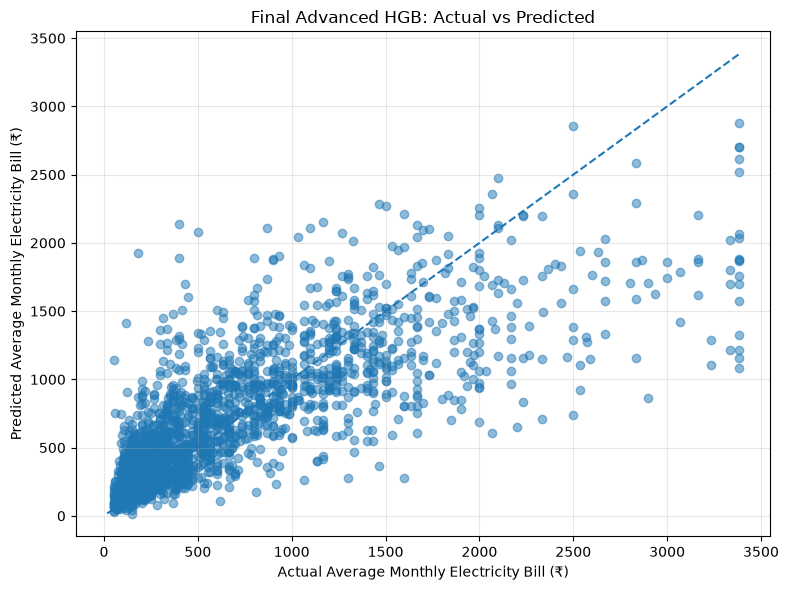

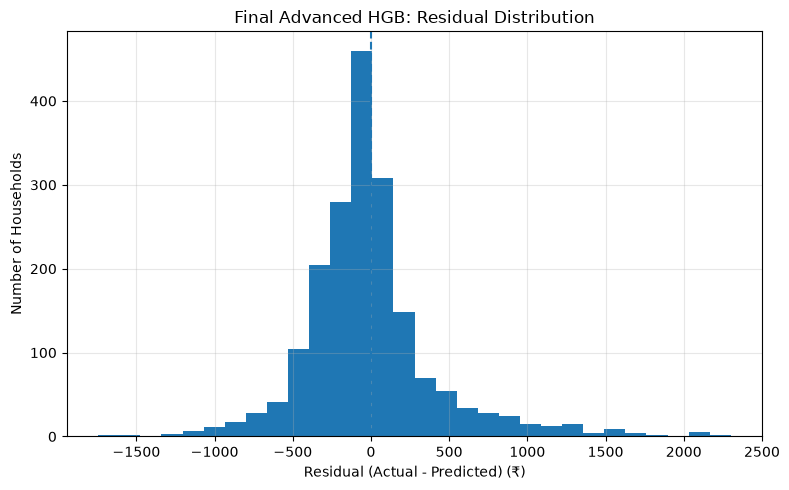

Mean residual: -9.62
Median residual: -47.85
Residual standard deviation: 428.78


In [439]:
# Plot actual vs predicted bills and the prediction residuals

import matplotlib.pyplot as plt
import numpy as np

actual_values_final = np.asarray(y_test)
residuals_final = actual_values_final - np.asarray(final_advanced_predictions)

# 1. Actual vs predicted plot
plt.figure(figsize=(8, 6))
plt.scatter(
    actual_values_final,
    final_advanced_predictions,
    alpha=0.5
)

minimum_value = min(actual_values_final.min(), final_advanced_predictions.min())
maximum_value = max(actual_values_final.max(), final_advanced_predictions.max())
plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Average Monthly Electricity Bill (₹)")
plt.ylabel("Predicted Average Monthly Electricity Bill (₹)")
plt.title("Final Advanced HGB: Actual vs Predicted")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Residual distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals_final, bins=30)
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (Actual - Predicted) (₹)")
plt.ylabel("Number of Households")
plt.title("Final Advanced HGB: Residual Distribution")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals_final.mean(), 2))
print("Median residual:", round(np.median(residuals_final), 2))
print("Residual standard deviation:", round(residuals_final.std(), 2))


## conclusion and model interpretation

### 1. Selected model

Five-fold cross-validation selected the **HistGradientBoosting model with all 10 engineered features** as the leading candidate. It achieved an average MAE of **₹287.642 (standard deviation ₹6.707)**, average RMSE of **433.810 (standard deviation 9.110)**, and average R² of **0.572 (standard deviation 0.013)**.

The baseline model achieved an average MAE of **₹288.359 (standard deviation ₹7.730)**, average RMSE of **434.681 (standard deviation 11.821)**, and average R² of **0.571 (standard deviation 0.012)**. The advanced model's average MAE improvement was only about **₹0.72**. Therefore, the cross-validation results indicate a **small improvement**, not a major increase in predictive performance.

### 2. Exploratory test-set comparison

| Metric | Baseline HGB | Selected HGB |
|---|---:|---:|
| MAE | ₹284.163 | ₹283.958 |
| RMSE | 427.868 | 428.887 |
| R² | 0.591 | 0.589 |

On the previously used test split, the selected model had a slightly lower MAE (by about ₹0.21), while the baseline had slightly lower RMSE and slightly higher R². These differences are very small. The test set was inspected during earlier development, so these metrics are **exploratory** and must not be presented as an untouched, unbiased final estimate.

### 3. Residual analysis

Residuals were calculated as **actual bill − predicted bill**.

- Mean residual: **−₹9.62**. The average signed error is close to zero and indicates slight average overprediction.
- Median residual: **−₹47.85**. The middle observation has a negative residual, meaning the prediction is ₹47.85 above the actual bill at the median.
- Residual standard deviation: **₹428.78**. This indicates substantial variation in prediction errors across households.

The actual-versus-predicted plot shows a clear positive relationship between actual and predicted bills, but the points become more dispersed at higher bill amounts. Many of the highest actual bills are below the perfect-prediction diagonal, suggesting that the model tends to underpredict some high-bill households. The residual histogram also has a wide spread and tails on both sides. Overall, predictions are not equally accurate across all bill levels.

### 4. Overall conclusion

The final model can estimate a household's **average monthly electricity bill amount** from the available survey features. Cross-validation showed that adding the engineered features produced a modest improvement over the baseline. The selected model is retained as the final candidate because it had the lowest average MAE across the five folds, while acknowledging that the gain was small and the exploratory test comparison was mixed.

### 5. Limitations

1. The target is electricity **bill amount in rupees**, not electricity consumption in kWh. The model does not directly measure energy consumption or identify electricity waste.
2. The dataset is survey-based. Predictions and feature relationships do not establish that any feature causes a household's electricity bill to increase or decrease.
3. The test split was inspected during earlier model development. A new, independent dataset or a genuinely untouched holdout set would be needed for a stronger unbiased estimate of generalization.
4. Residuals have a wide spread, and errors appear larger at higher bill amounts. Predictions should therefore be treated as estimates rather than exact bills, especially for households with high bills.
5. Performance for new locations, survey periods, or household populations has not been independently established by these experiments.

**Final takeaway:** The project successfully builds and evaluates a machine-learning model for average monthly electricity bill prediction. The advanced model is marginally better in cross-validation, but the improvement is limited. Further validation on independent data would be necessary before using the model for real-world decisions.
